# 🎓 Exploratory Data Analysis — World University Rankings 2018–2019

**Dataset:** `eighteen_nineteen_university_datasets.csv` — 1,000 universities, 12 columns (the layout and indicators match the CWUR *Center for World University Rankings* 2018–19 edition).

**Goals of this notebook**

| # | Step | What we do |
|---|------|-----------|
| 1 | Load & overview | Robust loading (encoding!), shape, dtypes, first look |
| 2 | Column-by-column review | A markdown description + a profile for **every** column |
| 3 | Non-numeric character detection | Prove which characters live inside the "numeric" columns |
| 4 | Missing-value handling | Find *hidden* missing values, understand them, impute responsibly |
| 5 | Outlier handling | IQR + z-score detection, decision per column, winsorising |
| 6 | Suspicious-value detection | Logical consistency rules + multivariate anomaly detection |
| 7 | Visual exploration | 15 plots (including a world map), each followed by an explanation |
| 8 | Summary & export | Key findings, decisions log, cleaned CSV |


## 0. Setup

In [1]:
import re, warnings, textwrap, unicodedata, collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (10, 5.5),
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
PALETTE = sns.color_palette("viridis", 8)

## 1. Loading the data & first look

The file is **not** UTF-8 (it contains Windows-1252 bytes such as `0xA0` – a non-breaking space), so a plain `pd.read_csv()` crashes with a `UnicodeDecodeError`. We try several encodings in order.

In [2]:
CANDIDATES = [
    Path("/kaggle/input/datasets/alifarajnia/eighteen-nineteen-university-datasets/eighteen_nineteen_university_datasets.csv"),
    Path("/kaggle/input/eighteen-nineteen-university-datasets/eighteen_nineteen_university_datasets.csv"),
]
DATA_PATH = next(p for p in CANDIDATES if p.exists())

def read_csv_robust(path):
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc), enc
        except UnicodeDecodeError:
            continue
    raise RuntimeError("Could not decode file")

df_raw, ENCODING = read_csv_robust(DATA_PATH)
print(f"Loaded with encoding: {ENCODING}  |  shape = {df_raw.shape}")
print("Raw column names:", list(df_raw.columns))

Loaded with encoding: cp1252  |  shape = (1000, 12)
Raw column names: ['World Rank', 'Institution', 'Location', 'National Rank', 'Quality\xa0of Education', 'Alumni Employment', 'Quality\xa0of Faculty', 'Research Output', 'Quality Publications', 'Influence', 'Citations', 'Score']


The raw header already shows a **data-quality problem**: `'Quality\xa0of Education'` and `'Quality\xa0of Faculty'` contain a *non-breaking space* (`\xa0`) instead of a normal space. Such names break `df["Quality of Education"]` lookups, so we normalise all column names.

In [3]:
df = df_raw.copy()
df.columns = (df.columns
              .str.replace("\xa0", " ", regex=False)
              .str.replace(r"\s+", " ", regex=True)
              .str.strip())
print(list(df.columns))
df.head(8)

['World Rank', 'Institution', 'Location', 'National Rank', 'Quality of Education', 'Alumni Employment', 'Quality of Faculty', 'Research Output', 'Quality Publications', 'Influence', 'Citations', 'Score']


,World Rank,Institution,Location,National Rank,Quality of Education,Alumni Employment,Quality of Faculty,Research Output,Quality Publications,Influence,Citations,Score
0,1,Harvard University,USA,1,2,1,1,1,1,1,1,100.0
1,2,Stanford University,USA,2,10,3,2,10,4,3,2,96.7
2,3,Massachusetts Institute of Technology,USA,3,3,11,3,30,15,2,6,95.1
3,4,University of Cambridge,United Kingdom,1,5,19,6,12,8,6,19,94.0
4,5,University of Oxford,United Kingdom,2,9,25,10,9,5,7,4,93.2
5,6,"University of California, Berkeley",USA,4,7,52,5,18,12,4,8,92.5
6,7,Princeton University,USA,5,4,15,4,146,99,28,27,91.9
7,8,Columbia University,USA,6,16,13,8,20,14,10,10,91.4


In [4]:
df.info()
print()
print("Duplicated rows:", df.duplicated().sum())
print("Native NaN cells:", int(df.isna().sum().sum()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   World Rank            1000 non-null   int64  
 1   Institution           1000 non-null   object 
 2   Location              1000 non-null   object 
 3   National Rank         1000 non-null   int64  
 4   Quality of Education  1000 non-null   object 
 5   Alumni Employment     1000 non-null   object 
 6   Quality of Faculty    1000 non-null   object 
 7   Research Output       1000 non-null   object 
 8   Quality Publications  1000 non-null   object 
 9   Influence             1000 non-null   object 
 10  Citations             1000 non-null   object 
 11  Score                 1000 non-null   float64
dtypes: float64(1), int64(2), object(9)
memory usage: 93.9+ KB

Duplicated rows: 0
Native NaN cells: 0


**First impressions**

* 1,000 rows × 12 columns; no native `NaN` and no duplicated rows — *but* seven indicator columns are stored as **text** (`str`/object) even though they should be numeric. That is a strong hint that non-numeric tokens are hiding inside them (investigated in Section 3).
* Only `World Rank`, `National Rank` and `Score` were parsed as numbers automatically.

## 2. Column-by-column review

For each column we give (a) a markdown description — meaning, expected type, how to read it — and (b) a short profile computed from the data. A small helper does the profiling.

In [5]:
IND = ["Quality of Education", "Alumni Employment", "Quality of Faculty",
       "Research Output", "Quality Publications", "Influence", "Citations"]
NUMERIC_COLS = ["World Rank", "National Rank"] + IND + ["Score"]

def profile(col, text_col=False, top=6):
    s = df[col]
    print(f"dtype = {s.dtype} | non-null = {s.notna().sum()} | unique = {s.nunique()}")
    if text_col:
        L = s.str.len()
        print(f"name length: min={L.min()}, mean={L.mean():.1f}, max={L.max()}")
        if s.nunique() < 200:
            print(s.value_counts().head(top).to_string())
        return
    num = pd.to_numeric(s, errors="coerce")
    tokens = s[num.isna()]
    if len(tokens):
        print(f"NON-NUMERIC tokens: {tokens.value_counts().to_dict()}  ({len(tokens)/len(s):.1%} of rows)")
    print(num.describe().round(2).to_string())
    print("most frequent numeric values:", num.value_counts().head(3).to_dict())

### 2.1 `World Rank`
**Meaning:** overall position of the university in the 2018–19 global list (1 = best).
**Expected type:** integer, ordinal (lower is better). Acts as the natural primary key.
**What to check:** completeness (1…1000), uniqueness, no gaps.

In [6]:
profile("World Rank")
print("Is exactly 1..1000 with no gaps/duplicates:", sorted(df["World Rank"]) == list(range(1, 1001)))

dtype = int64 | non-null = 1000 | unique = 1000
count    1000.00
mean      500.50
std       288.82
min         1.00
25%       250.75
50%       500.50
75%       750.25
max      1000.00
most frequent numeric values: {1000: 1, 1: 1, 2: 1}
Is exactly 1..1000 with no gaps/duplicates: True


### 2.2 `Institution`
**Meaning:** official English name of the university.
**Expected type:** free text, unique per row (identifier, not a feature).
**What to check:** duplicates, leading/trailing spaces, accents, and **corrupted characters** (some non-Latin letters may have been replaced by `?` when the file was exported).


In [7]:
profile("Institution", text_col=True)
print("\nLongest names:"); print(df.loc[df["Institution"].str.len().nlargest(3).index, "Institution"].to_string())
print("\nNames containing non-ASCII characters:", df["Institution"].str.contains(r"[^\x00-\x7f]").sum())
print("Names containing a literal '?':", df["Institution"].str.contains(r"\?").sum())

dtype = object | non-null = 1000 | unique = 1000
name length: min=5, mean=25.8, max=66

Longest names:
301    Chinese Academy of Medical Sciences & Peking U...
752    University of Natural Resources and Life Scien...
315    University of Texas Health Science Center at S...

Names containing non-ASCII characters: 70
Names containing a literal '?': 8


### 2.3 `Location`
**Meaning:** country / territory of the institution (Hong Kong, Macau and Taiwan appear as separate entries).
**Expected type:** categorical (nominal), 61 distinct labels.
**What to check:** label consistency (e.g. `USA` vs `United States`) and class imbalance — a few countries dominate.

In [8]:
profile("Location", text_col=True, top=8)

dtype = object | non-null = 1000 | unique = 61
name length: min=3, mean=6.3, max=15
Location
USA               213
China             108
United Kingdom     62
France             58
Japan              56
Germany            54
Italy              45
Spain              38


### 2.4 `National Rank`
**Meaning:** rank of the university *inside its own country* (1 = best domestic university).
**Expected type:** integer, ordinal, **restarts at 1 for every country**.
**What to check:** its maximum must equal the number of listed universities of the biggest country (the USA, 213); each country must have exactly one rank-1 institution.

In [9]:
profile("National Rank")

dtype = int64 | non-null = 1000 | unique = 213
count    1000.00
mean       40.02
std        49.23
min         1.00
25%         6.00
50%        21.00
75%        51.00
max       213.00
most frequent numeric values: {1: 61, 2: 48, 3: 45}


### 2.5 `Quality of Education`
**Meaning:** rank of the university by the **academic success of its alumni** (e.g. major international awards), relative to institution size. Lower = better.
**Expected type:** integer rank — but stored as **text** because some rows contain a dash `-` (= *not ranked* on this indicator).
**What to check:** share of dashes and the range of the numeric part.

In [10]:
profile("Quality of Education")

dtype = object | non-null = 1000 | unique = 404
NON-NUMERIC tokens: {'-': 597}  (59.7% of rows)
count    403.00
mean     323.41
std      194.08
min        1.00
25%      151.50
50%      321.00
75%      490.50
max      666.00
most frequent numeric values: {353.0: 1, 2.0: 1, 10.0: 1}


### 2.6 `Alumni Employment`
**Meaning:** rank by the **career success of alumni** (e.g. alumni holding top executive positions at leading companies), relative to institution size. Lower = better.
**Expected type:** integer rank; stored as text because of the token `> 1000` (*ranked below 1000, exact position unknown*).
**What to check:** about half of the universities fall into the `> 1000` bucket — this is **right-censoring**, not a typo.

In [11]:
profile("Alumni Employment")

dtype = object | non-null = 1000 | unique = 492
NON-NUMERIC tokens: {'> 1000': 509}  (50.9% of rows)
count    491.00
mean     441.99
std      285.38
min        1.00
25%      197.50
50%      414.00
75%      672.50
max      997.00
most frequent numeric values: {869.0: 1, 1.0: 1, 3.0: 1}


### 2.7 `Quality of Faculty`
**Meaning:** rank by the **academic achievements of the teaching staff** (major international awards). Lower = better.
**Expected type:** integer rank; text because of dashes `-` (*not ranked*).
**What to check:** this is the sparsest column — most universities have no award-winning faculty and therefore get no rank.

In [12]:
profile("Quality of Faculty")

dtype = object | non-null = 1000 | unique = 221
NON-NUMERIC tokens: {'-': 731}  (73.1% of rows)
count    269.00
mean     144.82
std       88.64
min        1.00
25%       68.00
50%      140.00
75%      223.00
max      303.00
most frequent numeric values: {141.0: 11, 164.0: 4, 194.0: 4}


### 2.8 `Research Output`
**Meaning:** rank by the **total volume of research papers** published. Lower = better.
**Expected type:** integer rank; text because of `> 1000`.
**What to check:** only ~8 % censored — research volume is the indicator that most universities can score on.

In [13]:
profile("Research Output")

dtype = object | non-null = 1000 | unique = 905
NON-NUMERIC tokens: {'> 1000': 77}  (7.7% of rows)
count     923.00
mean      467.36
std       274.99
min         1.00
25%       231.50
50%       462.00
75%       693.50
max      1000.00
most frequent numeric values: {204.0: 2, 720.0: 2, 428.0: 2}


### 2.9 `Quality Publications`
**Meaning:** rank by the number of papers published in **top-tier journals**. Lower = better.
**Expected type:** integer rank; text because of `> 1000`.
**What to check:** the least-censored column (≈5 %); very strongly related to `Research Output` and to the final `Score`.

In [14]:
profile("Quality Publications")

dtype = object | non-null = 1000 | unique = 892
NON-NUMERIC tokens: {'> 1000': 51}  (5.1% of rows)
count    949.00
mean     476.24
std      276.26
min        1.00
25%      238.00
50%      475.00
75%      712.00
max      997.00
most frequent numeric values: {724.0: 3, 969.0: 2, 730.0: 2}


### 2.10 `Influence`
**Meaning:** rank by the number of papers published in **highly influential journals**. Lower = better.
**Expected type:** integer rank; text because of `> 1000`.
**What to check:** ≈17 % censored; bridges "volume" and "citation" indicators.

In [15]:
profile("Influence")

dtype = object | non-null = 1000 | unique = 830
NON-NUMERIC tokens: {'> 1000': 171}  (17.1% of rows)
count    829.00
mean     431.83
std      264.50
min        1.00
25%      208.00
50%      416.00
75%      633.00
max      997.00
most frequent numeric values: {889.0: 1, 1.0: 1, 3.0: 1}


### 2.11 `Citations`
**Meaning:** rank by the number of **highly-cited papers**. Lower = better.
**Expected type:** integer rank; text because of `> 1000`.
**What to check:** an unusual structure — only ~74 distinct numeric values for ~890 rows. Huge groups of universities share *exactly the same rank* (**ties**), e.g. one value is repeated ≈130 times. We treat these as tied ranks, but they are flagged as "suspicious" in Section 6.

In [16]:
profile("Citations")

dtype = object | non-null = 1000 | unique = 75
NON-NUMERIC tokens: {'> 1000': 110}  (11.0% of rows)
count    890.00
mean     439.38
std      269.21
min        1.00
25%      222.00
50%      405.00
75%      673.00
max      898.00
most frequent numeric values: {898.0: 129, 673.0: 127, 541.0: 103}


### 2.12 `Score`
**Meaning:** the **overall composite score (0–100)** that determines `World Rank`; the best university is scaled to 100.
**Expected type:** float, continuous, one decimal.
**What to check:** monotonic relation with `World Rank`, skewed distribution (few very high scores, many near the cut-off ≈ 70).

In [17]:
profile("Score")
print(f"skewness = {df['Score'].skew():.2f} | excess kurtosis = {df['Score'].kurt():.2f}")

dtype = float64 | non-null = 1000 | unique = 195
count    1000.00
mean       75.03
std         4.67
min        69.80
25%        71.50
50%        73.75
75%        77.30
max       100.00
most frequent numeric values: {70.0: 16, 70.1: 16, 69.9: 16}
skewness = 1.44 | excess kurtosis = 2.48


## 3. Detecting non-numeric characters in the numeric columns

Ten columns *should* be purely numeric. We verify this at three levels:

1. **Value level** – which cells do **not** match the pattern `^\d+(\.\d+)?$`?
2. **Token level** – what exactly are the offending tokens (incl. hidden Unicode characters)?
3. **Character level** – the complete alphabet used in these columns.

In [18]:
PATTERN = r"\d+(\.\d+)?"

rows = []
for c in NUMERIC_COLS:
    s = df[c].astype(str)
    bad = s[~s.str.fullmatch(PATTERN)]
    rows.append({"column": c, "invalid_cells": len(bad),
                 "share_%": round(100 * len(bad) / len(s), 1),
                 "distinct_invalid_tokens": sorted(bad.unique().tolist())})
violations = pd.DataFrame(rows).set_index("column")
violations

,invalid_cells,share_%,distinct_invalid_tokens
column,,,
World Rank,0,0.0,[]
National Rank,0,0.0,[]
Quality of Education,597,59.7,[-]
Alumni Employment,509,50.9,[> 1000]
Quality of Faculty,731,73.1,[-]
Research Output,77,7.7,[> 1000]
Quality Publications,51,5.1,[> 1000]
Influence,171,17.1,[> 1000]
Citations,110,11.0,[> 1000]


In [19]:
# Token level: print code points so invisible characters (nbsp, zero-width…) cannot hide.
tokens = sorted({t for lst in violations["distinct_invalid_tokens"] for t in lst})
for t in tokens:
    print(f"{t!r:10} -> code points: {[hex(ord(ch)) for ch in t]}")

# Character level: every non-digit character that occurs in the numeric columns
chars = collections.Counter()
for c in NUMERIC_COLS:
    chars.update("".join(df[c].astype(str)))
alphabet = pd.DataFrame(
    [{"char": repr(ch), "unicode_name": unicodedata.name(ch, "?"), "occurrences": n}
     for ch, n in chars.items() if not ch.isdigit()]
).sort_values("occurrences", ascending=False).reset_index(drop=True)
alphabet

'-'        -> code points: ['0x2d']
'> 1000'   -> code points: ['0x3e', '0x20', '0x31', '0x30', '0x30', '0x30']


,char,unicode_name,occurrences
0,'-',HYPHEN-MINUS,1328
1,'.',FULL STOP,1000
2,'>',GREATER-THAN SIGN,918
3,' ',SPACE,918


In [20]:
# Hidden whitespace check (leading / trailing / non-breaking) on every numeric column
ws = {c: int(df[c].astype(str).str.contains(r"^\s|\s$|\xa0").sum()) for c in NUMERIC_COLS}
print("Cells with leading/trailing/non-breaking whitespace:", ws)

Cells with leading/trailing/non-breaking whitespace: {'World Rank': 0, 'National Rank': 0, 'Quality of Education': 0, 'Alumni Employment': 0, 'Quality of Faculty': 0, 'Research Output': 0, 'Quality Publications': 0, 'Influence': 0, 'Citations': 0, 'Score': 0}


**Findings**

* **No letters, currency signs, thousands separators, commas, or hidden Unicode characters** exist anywhere in the numeric columns. The only non-digit characters are `.` (decimal point in `Score`), `-`, `>` and the ordinary space inside the token `> 1000`.
* Exactly **two placeholder tokens** are responsible for *all* violations:
  * `-` → in `Quality of Education` and `Quality of Faculty`
  * `> 1000` → in `Alumni Employment`, `Research Output`, `Quality Publications`, `Influence`, `Citations`
* `World Rank`, `National Rank` and `Score` are 100 % clean.

These two tokens are **hidden missing values**: `df.isna()` reports zero missing cells, yet they carry no usable number. They also mean *different* things, so they must be handled differently (Section 4).

In [21]:
# Text columns: stray digits, doubled/leading/trailing spaces, '?' placeholders
for c in ["Institution", "Location"]:
    s = df[c]
    print(f"{c:12} | digits: {s.str.contains(r'\d').sum():3} | edge/double spaces: "
          f"{s.str.contains(r'^\s|\s$|\s{2,}').sum():3} | literal '?': {s.str.contains(r'\?').sum():3}")

Institution  | digits:   5 | edge/double spaces:   0 | literal '?':   8
Location     | digits:   0 | edge/double spaces:   0 | literal '?':   0


## 4. Missing-value handling

### 4.1 Standard vs. hidden missing values

In [22]:
TOK_DASH, TOK_GT = "-", "> 1000"

hidden = pd.DataFrame({
    "native_NaN": df[IND].isna().sum(),
    "'-'  (not ranked)": (df[IND] == TOK_DASH).sum(),
    "'> 1000'  (beyond list)": (df[IND] == TOK_GT).sum(),
})
hidden["total_hidden"] = hidden.iloc[:, 1:3].sum(axis=1)
hidden["hidden_%"] = (100 * hidden["total_hidden"] / len(df)).round(1)
hidden

,native_NaN,'-' (not ranked),'> 1000' (beyond list),total_hidden,hidden_%
Quality of Education,0,597,0,597,59.7
Alumni Employment,0,0,509,509,50.9
Quality of Faculty,0,731,0,731,73.1
Research Output,0,0,77,77,7.7
Quality Publications,0,0,51,51,5.1
Influence,0,0,171,171,17.1
Citations,0,0,110,110,11.0


### 4.2 What do the two tokens mean?

| Token | Columns | Interpretation | Type of missingness |
|-------|---------|----------------|---------------------|
| `-` | Education, Faculty | The university has **no award-winning alumni/staff**, so no rank is assigned. The largest numeric rank is only 666 / 303, i.e. unranked institutions are *behind* every ranked one. | **Informative** (MNAR – the absence *is* the signal) |
| `> 1000` | Alumni Employment, Research Output, Quality Publications, Influence, Citations | The rank exists but lies beyond position 1000. | **Right-censored** — we know the value is > 1000 |

Let's *see* the pattern before treating it.

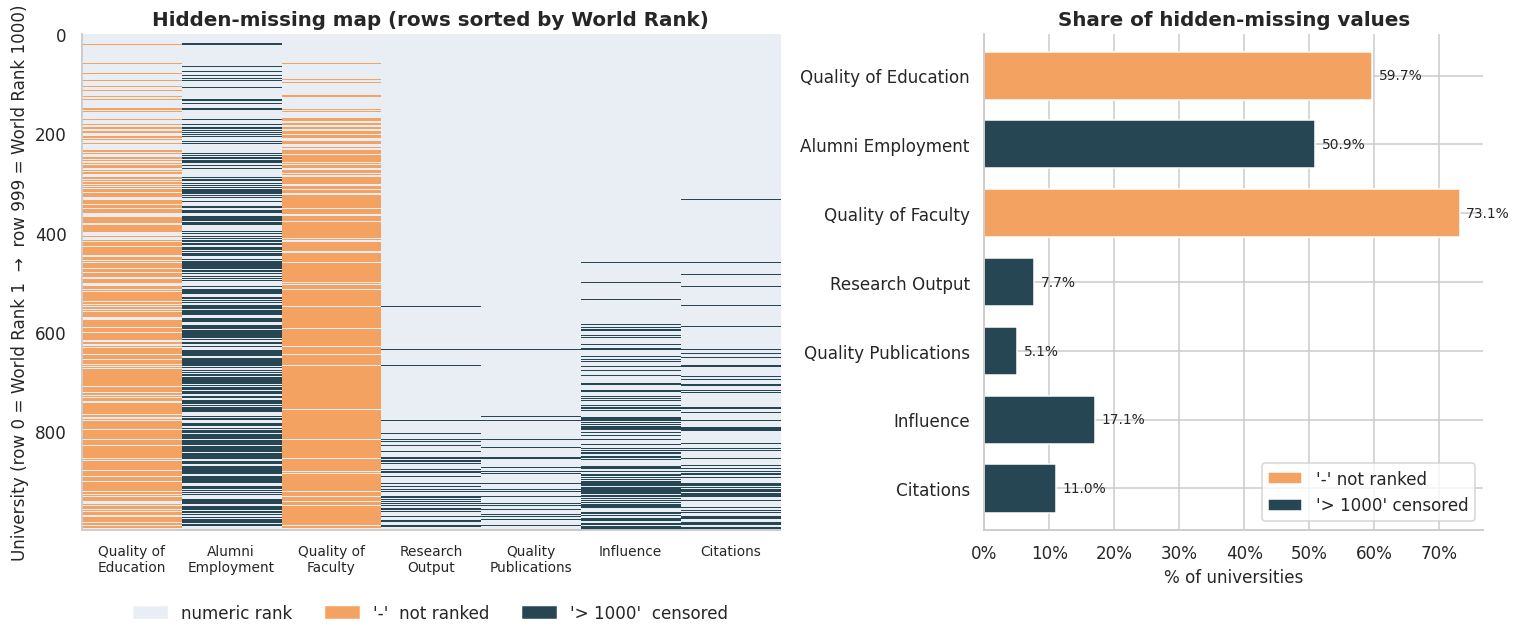

In [23]:
state = pd.DataFrame({c: np.where(df[c].eq(TOK_DASH), 1, np.where(df[c].eq(TOK_GT), 2, 0)) for c in IND})

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.4, 1]})
cmap = ListedColormap(["#e9eef4", "#f4a261", "#264653"])
axes[0].imshow(state.values, aspect="auto", cmap=cmap, interpolation="nearest")
axes[0].set_xticks(range(len(IND)))
axes[0].set_xticklabels([textwrap.fill(c, 12) for c in IND], fontsize=9)
axes[0].set_ylabel("University (row 0 = World Rank 1  →  row 999 = World Rank 1000)")
axes[0].set_title("Hidden-missing map (rows sorted by World Rank)")
axes[0].grid(False)
axes[0].legend(handles=[Patch(color="#e9eef4", label="numeric rank"),
                        Patch(color="#f4a261", label="'-'  not ranked"),
                        Patch(color="#264653", label="'> 1000'  censored")],
               loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)

share = pd.DataFrame({"'-' not ranked": (df[IND] == TOK_DASH).mean() * 100,
                      "'> 1000' censored": (df[IND] == TOK_GT).mean() * 100}).loc[IND[::-1]]
share.plot.barh(stacked=True, ax=axes[1], color=["#f4a261", "#264653"], width=.7)
axes[1].set_xlabel("% of universities"); axes[1].set_title("Share of hidden-missing values")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())
for i, (_, r) in enumerate(share.iterrows()):
    axes[1].text(r.sum() + 1, i, f"{r.sum():.1f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Reading the map.** Dark-orange blocks (`-`) are concentrated in the **lower part** of the table (weaker universities) and in just two columns; dark-teal blocks (`> 1000`) also thicken towards the bottom. Missingness is therefore **not random** — it grows as `World Rank` gets worse. Dropping rows or filling with the mean/median would distort the data. The bar chart shows how severe it is: `Quality of Faculty` (73 %) and `Quality of Education` (60 %) are missing for most universities, `Alumni Employment` for about half.

### 4.3 Is the missingness informative? (statistical test)

If the dash were random, the `Score` of "dash" and "non-dash" universities would look the same. We test with a Mann-Whitney U test (non-parametric, because `Score` is skewed).

,median_Score_unranked,median_Score_ranked,p_value
column,,,
Quality of Education,72.4,77.5,1.199169e-55
Quality of Faculty,72.6,79.8,1.163200e-76


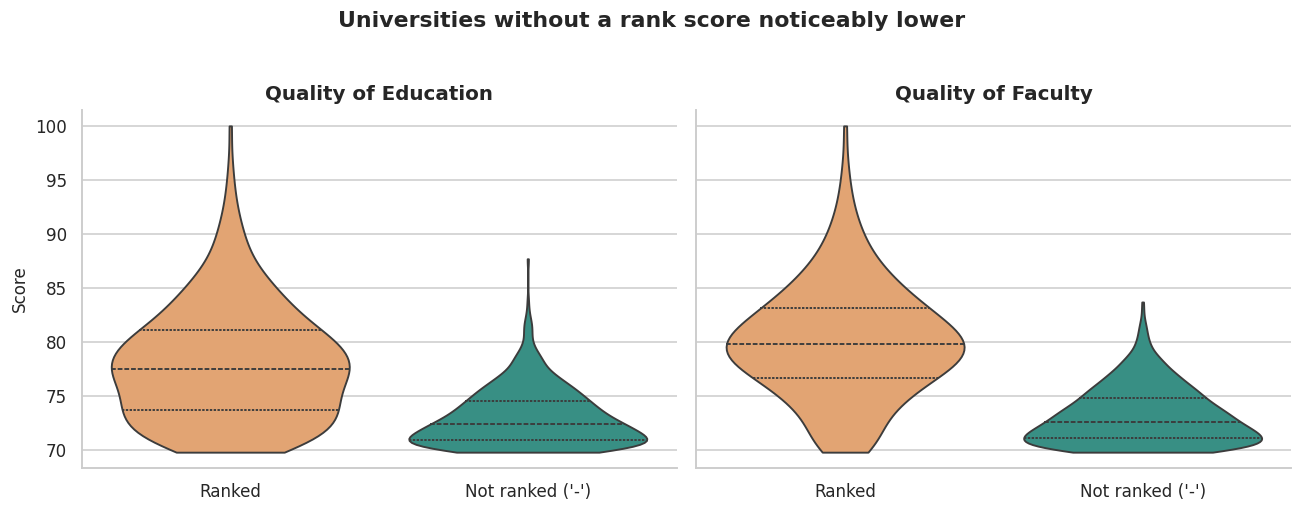

In [24]:
res = []
for c in ["Quality of Education", "Quality of Faculty"]:
    m = df[c].eq(TOK_DASH)
    u = stats.mannwhitneyu(df.loc[m, "Score"], df.loc[~m, "Score"])
    res.append({"column": c, "median_Score_unranked": df.loc[m, "Score"].median(),
                "median_Score_ranked": df.loc[~m, "Score"].median(), "p_value": u.pvalue})
display(pd.DataFrame(res).set_index("column"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, c in zip(axes, ["Quality of Education", "Quality of Faculty"]):
    tmp = pd.DataFrame({"Score": df["Score"], "status": np.where(df[c].eq(TOK_DASH), "Not ranked ('-')", "Ranked")})
    sns.violinplot(data=tmp, x="status", y="Score", hue="status", palette=["#f4a261", "#2a9d8f"],
                   inner="quart", cut=0, legend=False, ax=ax)
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Universities without a rank score noticeably lower", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()

The p-values are essentially zero and the violins barely overlap: universities with `-` have clearly lower `Score`s. The missingness is **MNAR (missing not at random)** — so mean/median imputation would be wrong, and *the fact of being unranked* is itself a useful feature.

### 4.4 Treatment strategy

| Step | Action | Why |
|------|--------|-----|
| 1 | Convert both tokens to `NaN` and parse the rest to numbers → **`df_obs`** (observed values only) | Keeps a truthful table for statistics such as outlier detection |
| 2 | Add boolean flags `<col>_unranked` and `<col>_gt1000` | Preserves the information carried by the missingness |
| 3 | `> 1000` → **1001** (just beyond the list) | Censored values are *worse than every listed rank*; 1001 keeps the order and is the smallest consistent choice |
| 4 | `-` → **(largest observed rank in that column) + 1** | Unranked universities are *behind all ranked ones*; avoids pretending they are "average" |
| 5 | Do **not** drop columns or rows | 60–73 % missing is too much to delete, and rows are the unit of analysis |

Both fills keep the rank **ordering**, so rank-based statistics (Spearman correlation, boxplots, tree models) stay valid. Use the flags (or the `df_obs` table) whenever the exact fill value could matter (e.g. linear models).

In [25]:
df_obs = df[["World Rank", "Institution", "Location", "National Rank", "Score"]].copy()
df_clean = df_obs.copy()
fill_info = {}

for c in IND:
    raw = df[c].astype(str).str.strip()
    is_dash, is_gt = raw.eq(TOK_DASH), raw.eq(TOK_GT)
    num = pd.to_numeric(raw.mask(is_dash | is_gt), errors="raise")   # raises if ANY other garbage exists
    df_obs[c] = num
    if is_dash.any(): df_clean[f"{c}_unranked"] = is_dash
    if is_gt.any():   df_clean[f"{c}_gt1000"] = is_gt
    fill = 1001 if is_gt.any() else int(num.max()) + 1
    df_clean[c] = num.fillna(fill).astype(int)
    fill_info[c] = {"observed": int(num.notna().sum()), "filled": int(num.isna().sum()), "fill_value": fill}

df_clean = df_clean[["World Rank", "Institution", "Location", "National Rank"] + IND + ["Score"]
                    + [c for c in df_clean.columns if c.endswith(("_unranked", "_gt1000"))]]

print("Remaining NaN after treatment:", int(df_clean.isna().sum().sum()))
print("dtypes of indicators:", set(df_clean[IND].dtypes.astype(str)))
pd.DataFrame(fill_info).T

Remaining NaN after treatment: 0
dtypes of indicators: {'int64'}


,observed,filled,fill_value
Quality of Education,403,597,667
Alumni Employment,491,509,1001
Quality of Faculty,269,731,304
Research Output,923,77,1001
Quality Publications,949,51,1001
Influence,829,171,1001
Citations,890,110,1001


✅ The `errors="raise"` in `pd.to_numeric` doubles as a **proof**: had a single unexpected character survived, the cell would have failed. All ten numeric columns are now truly numeric, with no `NaN`.

## 5. Outlier handling

**Approach.** We detect outliers on the *observed* values only (`df_obs`), because the imputed `1001` placeholders would otherwise create artificial pile-ups. Two methods are used:

* **Tukey IQR rule:** outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`
* **z-score rule:** `|z| > 3`

An outlier is *not automatically an error* — in a ranking, the very best universities are legitimately far from the rest.

In [26]:
OUT_COLS = ["Score", "National Rank"] + IND

def iqr_fences(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in OUT_COLS:
    s = df_obs[c].dropna()
    lo, hi = iqr_fences(s)
    rows.append({"column": c, "n_observed": len(s), "skew": round(s.skew(), 2),
                 "lower_fence": round(lo, 1), "upper_fence": round(hi, 1),
                 "IQR_outliers": int(((s < lo) | (s > hi)).sum()),
                 "z>3_outliers": int((np.abs(stats.zscore(s)) > 3).sum())})
outlier_table = pd.DataFrame(rows).set_index("column")
outlier_table

,n_observed,skew,lower_fence,upper_fence,IQR_outliers,z>3_outliers
column,,,,,,
Score,1000,1.44,62.8,86.0,33,15
National Rank,1000,1.79,-61.5,118.5,95,26
Quality of Education,403,0.02,-357.0,999.0,0,0
Alumni Employment,491,0.21,-515.0,1385.0,0,0
Quality of Faculty,269,0.13,-164.5,455.5,0,0
Research Output,923,0.08,-461.5,1386.5,0,0
Quality Publications,949,0.03,-473.0,1423.0,0,0
Influence,829,0.24,-429.5,1270.5,0,0
Citations,890,0.26,-454.5,1349.5,0,0


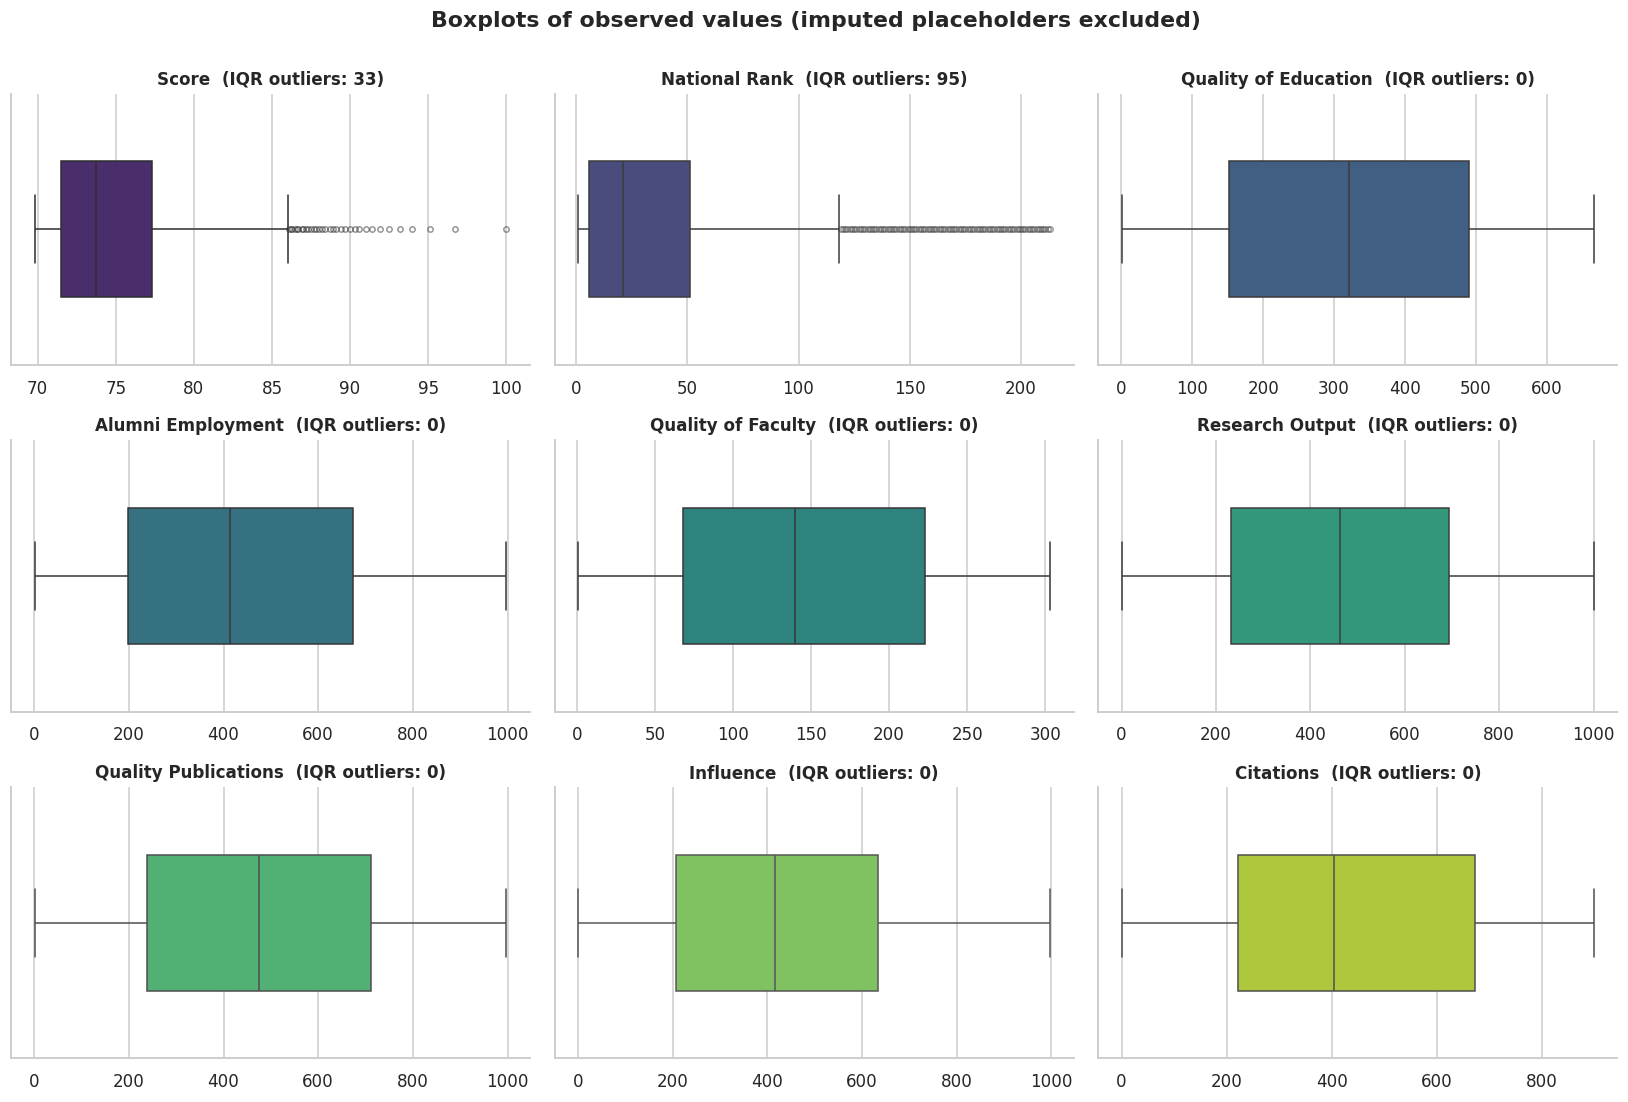

In [27]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c, col in zip(axes.ravel(), OUT_COLS, sns.color_palette("viridis", len(OUT_COLS))):
    s = df_obs[c].dropna()
    sns.boxplot(x=s, ax=ax, color=col, width=.5, flierprops=dict(marker="o", markersize=3.5, alpha=.5))
    ax.set_title(f"{c}  (IQR outliers: {outlier_table.loc[c, 'IQR_outliers']})", fontsize=11)
    ax.set_xlabel("")
plt.suptitle("Boxplots of observed values (imputed placeholders excluded)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

**Interpretation**

* **`Score`** is the only indicator-like column with real *upper* outliers (33 universities above the IQR fence of 86.0; 15 with |z| > 3). These are the world's elite institutions (Harvard, Stanford, MIT, Cambridge, Oxford …). They are **genuine, not errors**.
* **The seven rank indicators show 0 IQR outliers** (skewness ≈ 0–0.26): observed ranks are spread almost uniformly between 1 and ≈1000, so no value sits far from the bulk.
* **`National Rank`** has 95 IQR outliers, but they are not errors: they are deep positions inside big systems (USA up to 213, China up to 108).
* No value is impossible (no negatives, nothing above 1000 among observed ranks, no `Score` outside 0–100).

### Treatment decision

| Column(s) | Decision | Reason |
|-----------|----------|--------|
| `Score` | **Keep** original, add `Score_winsor` (capped at the upper IQR fence) and `Score_log` | Values are valid; transformed versions help models/plots sensitive to skew |
| 7 rank indicators | **Keep unchanged** | Ordinal & bounded; extreme values are real achievements, not noise |
| `National Rank` | **Keep** | Large values reflect country size, not errors |

,min,max,mean,skew
Score,69.800,100.000,75.034,1.442
Score_winsor,69.800,86.000,74.915,0.988
Score_log,4.246,4.605,4.316,1.247


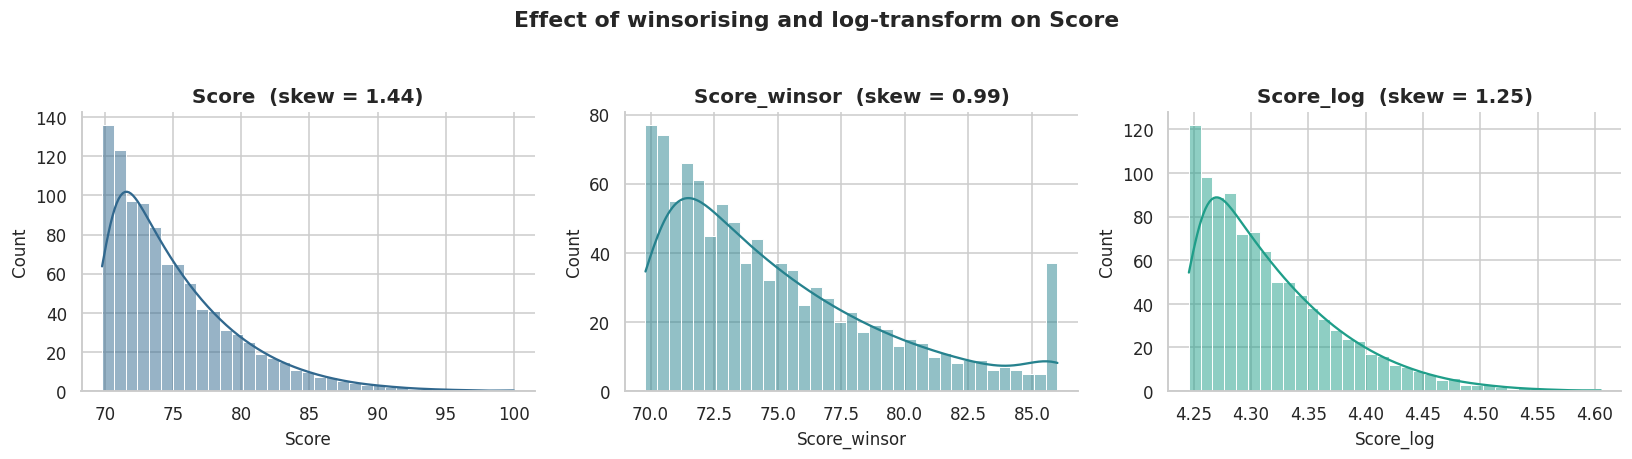

Top-10 'outliers' (all legitimate):


,World Rank,Institution,Location,Score
0,1,Harvard University,USA,100.0
1,2,Stanford University,USA,96.7
2,3,Massachusetts Institute of Technology,USA,95.1
3,4,University of Cambridge,United Kingdom,94.0
4,5,University of Oxford,United Kingdom,93.2
5,6,"University of California, Berkeley",USA,92.5
6,7,Princeton University,USA,91.9
7,8,Columbia University,USA,91.4
8,9,California Institute of Technology,USA,91.0
9,10,University of Chicago,USA,90.6


In [28]:
_, hi = iqr_fences(df_clean["Score"])
df_clean["Score_winsor"] = df_clean["Score"].clip(upper=hi)
df_clean["Score_log"] = np.log(df_clean["Score"])

cmp = pd.DataFrame({v: {"min": df_clean[v].min(), "max": df_clean[v].max(),
                        "mean": df_clean[v].mean(), "skew": df_clean[v].skew()}
                    for v in ["Score", "Score_winsor", "Score_log"]}).T.round(3)
display(cmp)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, v, col in zip(axes, ["Score", "Score_winsor", "Score_log"], PALETTE[2:5]):
    sns.histplot(df_clean[v], bins=35, kde=True, color=col, ax=ax)
    ax.set_title(f"{v}  (skew = {df_clean[v].skew():.2f})")
plt.suptitle("Effect of winsorising and log-transform on Score", fontweight="bold", y=1.04)
plt.tight_layout(); plt.show()

print("Top-10 'outliers' (all legitimate):")
df_clean.loc[df_clean["Score"] > hi, ["World Rank", "Institution", "Location", "Score"]].head(10)

Winsorising reduces the skewness from 1.44 to 0.99 (the maximum drops from 100 to 86), while the log-transform lowers it only slightly (1.25) but keeps the original ordering and every value. We keep all three versions; downstream work can choose whichever fits the model.

## 6. Suspicious-value detection

We combine **rule-based consistency checks** (things that *must* be true in a clean ranking) with an **unsupervised multivariate detector** (Isolation Forest) that looks for universities whose *combination* of indicators is unusual.

### 6.1 Rule-based checks

In [29]:
checks = []
def add(name, ok, detail=""):
    checks.append({"check": name, "result": "✅ pass" if ok else "⚠️ FLAG", "detail": detail})

d = df_clean
# 1 identifiers
add("World Rank is exactly 1..1000, unique", sorted(d["World Rank"]) == list(range(1, 1001)))
# 2 score logic
inc = int((d["Score"].diff() > 0).sum())
add("Score within [0, 100]", d["Score"].between(0, 100).all(), f"min={d['Score'].min()}, max={d['Score'].max()}")
add("Score never increases as World Rank gets worse", inc == 0, f"{inc} violations")
add("Exactly one university has Score = 100", (d["Score"] == 100).sum() == 1)
# 3 national rank logic
g = d.sort_values("World Rank").groupby("Location")
ok_start = (g["National Rank"].min() == 1).all()
ok_max   = (g["National Rank"].max() == g.size()).all()
ok_mono  = g["National Rank"].apply(lambda s: s.is_monotonic_increasing and s.is_unique).all()
add("Every country starts at National Rank 1", ok_start)
add("Max National Rank == number of universities of that country", ok_max)
add("National Rank strictly increases with World Rank inside each country", ok_mono)
# 4 duplicates & text hygiene
norm = d["Institution"].str.lower().str.replace(r"[^a-z]", "", regex=True)
add("No duplicate institutions (case/punctuation-insensitive)", not norm.duplicated().any(), f"{int(norm.duplicated().sum())} duplicates")
add("No leading/trailing/double spaces in names", not d["Institution"].str.contains(r"^\s|\s$|\s{2,}").any())
bad_q = d["Institution"].str.contains(r"\?")
add("No corrupted characters ('?') in institution names", not bad_q.any(), f"{int(bad_q.sum())} names affected")
# 5 country labels
loc = d["Location"].unique()
alias = [x for x in loc if x in {"United States", "US", "U.S.", "UK", "England", "Korea", "Russian Federation"}]
add("No alias/duplicate country labels", len(alias) == 0 and len({x.lower().strip() for x in loc}) == len(loc), f"{len(loc)} labels")
# 6 domain of ranks
add("All indicator ranks ≥ 1", (d[IND] >= 1).all().all())
add("Observed (non-imputed) ranks never exceed 1000", (df_obs[IND].max() <= 1000).all(), f"max observed = {int(df_obs[IND].max().max())}")

pd.DataFrame(checks)

,check,result,detail
0,"World Rank is exactly 1..1000, unique",✅ pass,
1,"Score within [0, 100]",✅ pass,"min=69.8, max=100.0"
2,Score never increases as World Rank gets worse,✅ pass,0 violations
3,Exactly one university has Score = 100,✅ pass,
4,Every country starts at National Rank 1,✅ pass,
5,Max National Rank == number of universities of...,✅ pass,
6,National Rank strictly increases with World Ra...,✅ pass,
7,No duplicate institutions (case/punctuation-in...,✅ pass,0 duplicates
8,No leading/trailing/double spaces in names,✅ pass,
9,No corrupted characters ('?') in institution n...,⚠️ FLAG,8 names affected


**Result.** The ranking logic is internally consistent (ranks, scores and national ranks all line up) — but the text hygiene check exposes a real defect: **some institution names contain a literal `?`** where an accented letter used to be. Let's look.

In [30]:
d.loc[bad_q, ["World Rank", "Institution", "Location"]]

,World Rank,Institution,Location
739,740,Bo?aziçi University,Turkey
740,741,Adam Mickiewicz University in Pozna?,Poland
775,776,University of Wroc?aw,Poland
801,802,Babe?-Bolyai University,Romania
843,844,Wroc?aw University of Science and Technology,Poland
929,930,University of South Bohemia in ?eské Bud?jovice,Czech Republic
953,954,Nicolaus Copernicus University in Toru?,Poland
997,998,K?chi University,Japan


These are Turkish, Polish, Romanian, Czech and Japanese letters (`ğ, ł, ń, ș, č, ě, ō …`) that were irreversibly replaced by `?` when the file was created, so no re-encoding trick can restore them. Because each name is a well-known institution, we repair them with a **manual mapping** and keep a flag column for transparency.

In [31]:
NAME_FIX = {
    "Bo?aziçi University": "Boğaziçi University",
    "Adam Mickiewicz University in Pozna?": "Adam Mickiewicz University in Poznań",
    "University of Wroc?aw": "University of Wrocław",
    "Babe?-Bolyai University": "Babeș-Bolyai University",
    "Wroc?aw University of Science and Technology": "Wrocław University of Science and Technology",
    "University of South Bohemia in ?eské Bud?jovice": "University of South Bohemia in České Budějovice",
    "Nicolaus Copernicus University in Toru?": "Nicolaus Copernicus University in Toruń",
    "K?chi University": "Kōchi University",
}
df_clean["name_repaired"] = df_clean["Institution"].isin(NAME_FIX)
df_clean["Institution"] = df_clean["Institution"].replace(NAME_FIX)
print("Names still containing '?':", int(df_clean["Institution"].str.contains(r"\?").sum()))
df_clean.loc[df_clean["name_repaired"], ["World Rank", "Institution"]]

Names still containing '?': 0


,World Rank,Institution
739,740,Boğaziçi University
740,741,Adam Mickiewicz University in Poznań
775,776,University of Wrocław
801,802,Babeș-Bolyai University
843,844,Wrocław University of Science and Technology
929,930,University of South Bohemia in České Budějovice
953,954,Nicolaus Copernicus University in Toruń
997,998,Kōchi University


### 6.2 Plateaus / suspiciously repeated values

A genuine rank list should contain mostly *distinct* values. Large groups sharing the same value deserve attention.

,observed,distinct_values,most_common_value,its_count,share_of_observed_%
column,,,,,
Quality of Education,403,403,353.0,1,0.2
Alumni Employment,491,491,869.0,1,0.2
Quality of Faculty,269,220,141.0,11,4.1
Research Output,923,904,204.0,2,0.2
Quality Publications,949,891,724.0,3,0.3
Influence,829,829,889.0,1,0.1
Citations,890,74,898.0,129,14.5


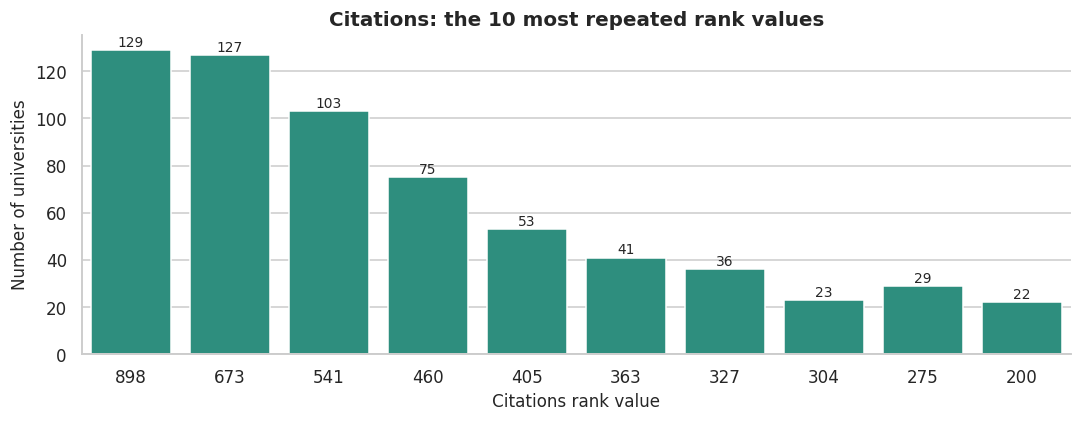

In [32]:
rows = []
for c in IND:
    s = df_obs[c].dropna()
    vc = s.value_counts()
    rows.append({"column": c, "observed": len(s), "distinct_values": s.nunique(),
                 "most_common_value": vc.index[0], "its_count": vc.iloc[0],
                 "share_of_observed_%": round(100 * vc.iloc[0] / len(s), 1)})
plateau = pd.DataFrame(rows).set_index("column")
display(plateau)

top_c = df_obs["Citations"].value_counts().head(10).sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=top_c.index.astype(int).astype(str), y=top_c.values, color=PALETTE[4], ax=ax)
ax.set_xlabel("Citations rank value"); ax.set_ylabel("Number of universities")
ax.set_title("Citations: the 10 most repeated rank values")
for i, v in enumerate(top_c.values): ax.text(i, v + 1.5, v, ha="center", fontsize=9)
plt.tight_layout(); plt.show()

**`Citations` is clearly different from every other indicator.** Its observed values collapse into a *staircase* of tied ranks: a single rank value (898) is shared by well over a hundred universities, and the next few plateaus (673, 541, 460 …) are similarly crowded. This is how ties are reported when many institutions have an identical (typically very small) number of highly-cited papers.

**Consequences:** (i) `Citations` has much less resolution than the other columns, (ii) outlier/variance statistics on it should be interpreted cautiously, (iii) rank-based methods (Spearman) are the safest choice. We keep the values — they are not errors — but flag the column as **low-resolution**.

### 6.3 Multivariate anomaly detection (Isolation Forest)

A university can look normal in every single column yet have an odd *profile* — e.g. superb research volume but zero influence. Isolation Forest isolates such rows quickly. We work on log-ranks (so that rank 5 vs 10 matters as much as 500 vs 1000) plus `Score`.

In [33]:
X = np.log10(df_clean[IND]).copy()
X["Score"] = df_clean["Score"]
iso = IsolationForest(n_estimators=400, contamination=0.02, random_state=42)
df_clean["anomaly_flag"] = iso.fit_predict(X) == -1
df_clean["anomaly_score"] = -iso.score_samples(X)           # higher = more unusual

print("Flagged:", int(df_clean["anomaly_flag"].sum()), "universities (2 %)")
cols = ["World Rank", "Institution", "Location", "Score"] + IND
df_clean.loc[df_clean["anomaly_flag"]].sort_values("anomaly_score", ascending=False)[cols + ["anomaly_score"]].head(12).round(3)

Flagged: 20 universities (2 %)


,World Rank,Institution,Location,Score,Quality of Education,Alumni Employment,Quality of Faculty,Research Output,Quality Publications,Influence,Citations,anomaly_score
0,1,Harvard University,USA,100.0,2,1,1,1,1,1,1,0.814
1,2,Stanford University,USA,96.7,10,3,2,10,4,3,2,0.785
2,3,Massachusetts Institute of Technology,USA,95.1,3,11,3,30,15,2,6,0.765
4,5,University of Oxford,United Kingdom,93.2,9,25,10,9,5,7,4,0.743
3,4,University of Cambridge,United Kingdom,94.0,5,19,6,12,8,6,19,0.738
5,6,"University of California, Berkeley",USA,92.5,7,52,5,18,12,4,8,0.734
15,16,Johns Hopkins University,USA,88.9,24,159,17,8,6,12,3,0.718
7,8,Columbia University,USA,91.4,16,13,8,20,14,10,10,0.712
6,7,Princeton University,USA,91.9,4,15,4,146,99,28,27,0.711
16,17,University of Toronto,Canada,88.7,86,157,23,2,2,16,7,0.708


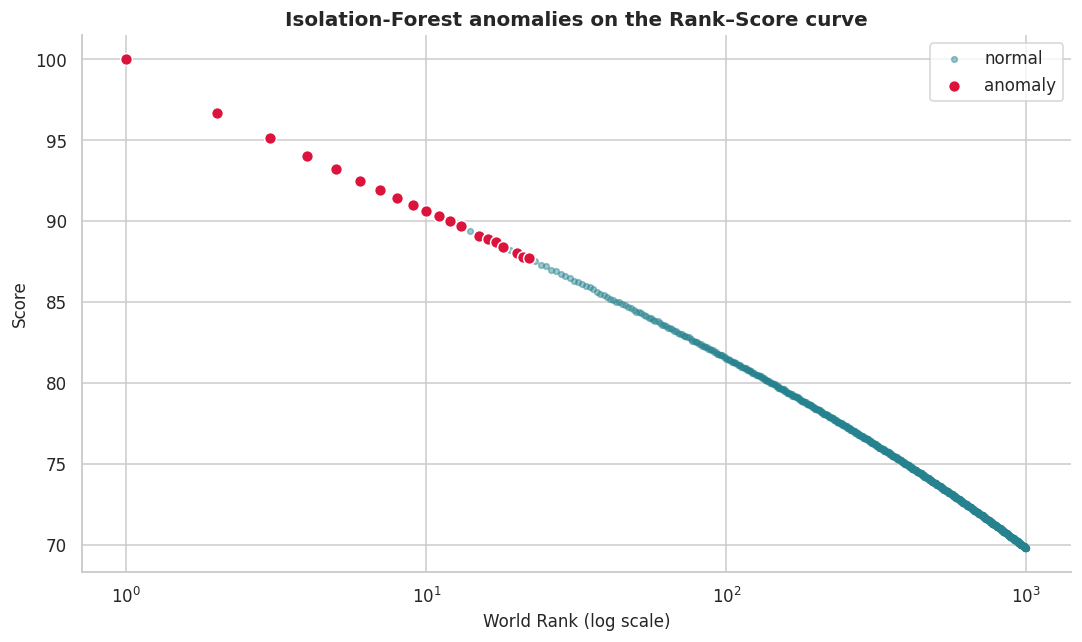

In [34]:
fig, ax = plt.subplots(figsize=(10, 6))
norm_ = df_clean[~df_clean["anomaly_flag"]]; anom = df_clean[df_clean["anomaly_flag"]]
ax.scatter(norm_["World Rank"], norm_["Score"], s=14, alpha=.45, color=PALETTE[3], label="normal")
ax.scatter(anom["World Rank"], anom["Score"], s=60, color="crimson", edgecolor="white", label="anomaly")
ax.set_xscale("log"); ax.set_xlabel("World Rank (log scale)"); ax.set_ylabel("Score"); ax.legend()
ax.set_title("Isolation-Forest anomalies on the Rank–Score curve")
plt.tight_layout(); plt.show()

**Interpretation.** All 20 flagged universities lie within the **world's top 22** (Harvard, Stanford, MIT, Cambridge, Oxford, Berkeley, Johns Hopkins …). They are isolated simply because the elite occupy a sparse corner of the feature space (tiny ranks *and* very high scores). A few are also genuinely **lopsided**: Princeton ranks 4th in Education but only 146th in Research Output; the University of Toronto is 2nd in Research Output but 86th in Education; Johns Hopkins is 8th in Research Output but 159th in Alumni Employment. These are *unusual but plausible* profiles, not data errors. They are **not removed**; the `anomaly_flag` column is kept so analysts can inspect or exclude them.

**Suspicious-value summary**

| Issue | Rows | Action |
|-------|------|--------|
| Corrupted characters (`?`) in names | 8 | Repaired manually, flagged in `name_repaired` |
| Non-breaking spaces in 2 column names | 2 columns | Normalised |
| Hidden placeholders (`-`, `> 1000`) | up to 73 % per column | Flagged + imputed (Section 4) |
| Tied-rank plateaus in `Citations` | ≈ 5 groups of 50–130 rows | Kept, documented as low-resolution |
| Multivariate anomalies | 20 | Kept, flagged in `anomaly_flag` |

## 7. Visual exploration

First, a few helper columns used by several plots: **Region** (continent-level grouping of the 61 countries), **Rank band**, and a log-scaled **"strength"** version of the ranks (1 = best, 0 = worst) which makes ranks comparable on one axis.

In [35]:
REGION = {
 "Argentina":"South America","Brazil":"South America","Chile":"South America","Colombia":"South America","Uruguay":"South America",
 "Canada":"North America","Mexico":"North America","USA":"North America",
 "Australia":"Oceania","New Zealand":"Oceania",
 "Egypt":"Africa","Nigeria":"Africa","South Africa":"Africa","Tunisia":"Africa","Uganda":"Africa",
 "China":"Asia","Hong Kong":"Asia","India":"Asia","Iran":"Asia","Israel":"Asia","Japan":"Asia","Lebanon":"Asia","Macau":"Asia",
 "Malaysia":"Asia","Pakistan":"Asia","Saudi Arabia":"Asia","Singapore":"Asia","South Korea":"Asia","Taiwan":"Asia","Thailand":"Asia","Turkey":"Asia",
}
d = df_clean
d["Region"] = d["Location"].map(REGION).fillna("Europe")        # all remaining labels are European countries
d["Rank band"] = pd.cut(d["World Rank"], [0, 100, 250, 500, 1000],
                        labels=["Top 100", "101–250", "251–500", "501–1000"])
def strength(rank): return 1 - np.log10(rank) / np.log10(1001)  # 1 = best, ~0 = rank 1000+

REGION_COLORS = dict(zip(["North America", "Europe", "Asia", "Oceania", "South America", "Africa"],
                         ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "#8d5a97"]))
print(d["Region"].value_counts().to_string())
assert d["Region"].notna().all()

Region
Europe           389
Asia             291
North America    245
South America     31
Oceania           30
Africa            14


### 7.1 Distribution of the overall `Score`

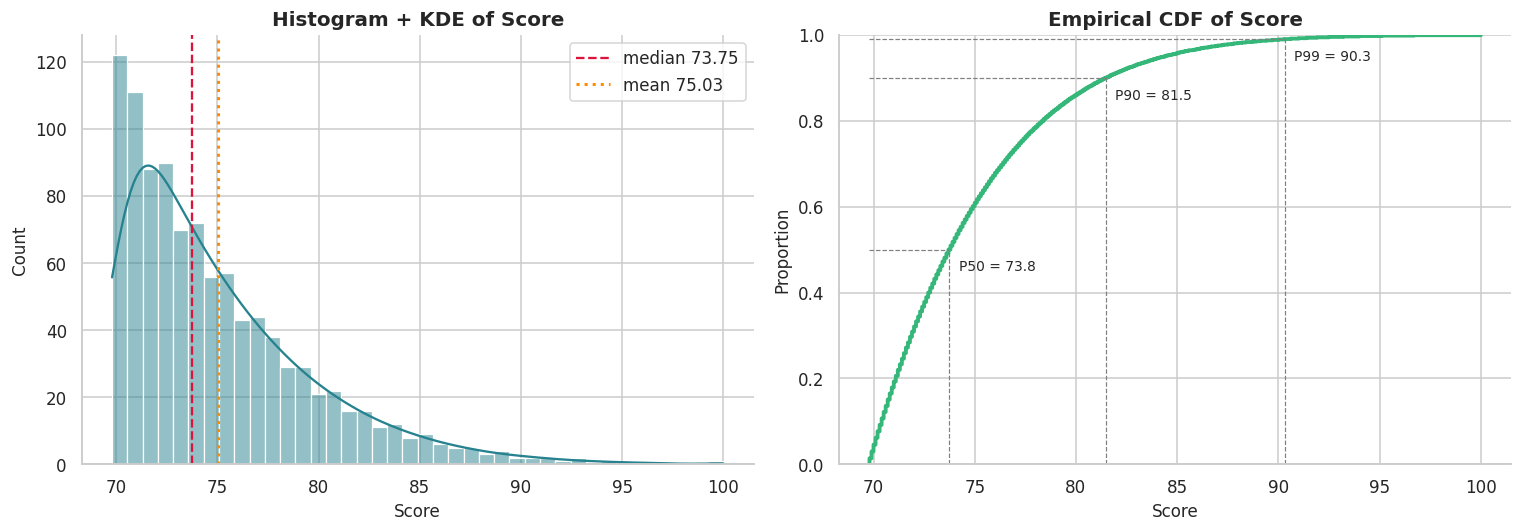

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(d["Score"], bins=40, kde=True, color=PALETTE[3], ax=axes[0])
axes[0].axvline(d["Score"].median(), color="crimson", ls="--", label=f"median {d['Score'].median():.2f}")
axes[0].axvline(d["Score"].mean(), color="darkorange", ls=":", lw=2, label=f"mean {d['Score'].mean():.2f}")
axes[0].legend(); axes[0].set_title("Histogram + KDE of Score")

sns.ecdfplot(d["Score"], color=PALETTE[5], lw=2.5, ax=axes[1])
for q in (.5, .9, .99):
    v = d["Score"].quantile(q)
    axes[1].plot([d["Score"].min(), v], [q, q], color="grey", lw=.8, ls="--")
    axes[1].plot([v, v], [0, q], color="grey", lw=.8, ls="--")
    axes[1].annotate(f"P{int(q*100)} = {v:.1f}", (v, q), textcoords="offset points", xytext=(6, -14), fontsize=9)
axes[1].set_title("Empirical CDF of Score")
plt.tight_layout(); plt.show()

**Insights.** The score is strongly **right-skewed** (skewness ≈ 1.4): the median (73.75) sits below the mean (75.03) and half of all 1,000 universities are packed into a narrow 69.8–73.8 window. The ECDF shows how steep the climb is at the beginning and how thin the tail is — only the top 10 % exceed ≈ 81.5 and only the top 1 % exceed ≈ 90. Being "in the top 1000" is a fairly flat crowd; being in the top 100 is a different league.

### 7.2 The Rank–Score curve

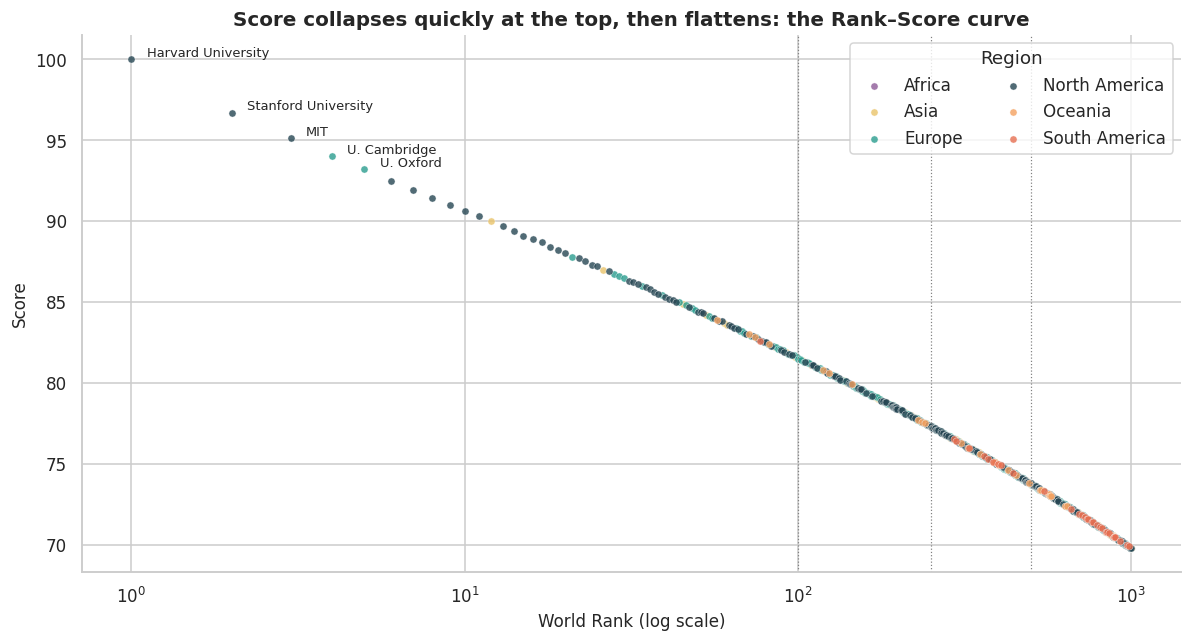

In [37]:
fig, ax = plt.subplots(figsize=(11, 6))
for reg, sub in d.groupby("Region"):
    ax.scatter(sub["World Rank"], sub["Score"], s=22, alpha=.8, color=REGION_COLORS[reg], label=reg, edgecolor="white", linewidth=.3)
ax.set_xscale("log"); ax.set_xlabel("World Rank (log scale)"); ax.set_ylabel("Score")
for _, r in d.nsmallest(5, "World Rank").iterrows():
    ax.annotate(r["Institution"].replace("Massachusetts Institute of Technology", "MIT").replace("University of", "U."),
                (r["World Rank"], r["Score"]), textcoords="offset points", xytext=(10, 2), fontsize=8.5)
for edge in (100, 250, 500):
    ax.axvline(edge, color="grey", ls=":", lw=.8)
ax.legend(title="Region", ncol=2, frameon=True, loc="upper right")
ax.set_title("Score collapses quickly at the top, then flattens: the Rank–Score curve")
plt.tight_layout(); plt.show()

**Insights.** Because the x-axis is logarithmic, the curve reveals two regimes: a **steep cliff** inside the top ≈ 20 (Harvard 100 → 88.0 at rank 20, then only 81.5 at rank 100) and a **long, nearly flat plateau** afterwards (≈ 70 at rank 1000). Between rank 500 and 1000 the score only changes by about 4 points — tiny differences in score translate into hundreds of rank positions. Colours also show geography: the top-left corner is almost entirely North-American (and a few European) universities, while Asian points populate the right half of the plot.

### 7.3 Country representation

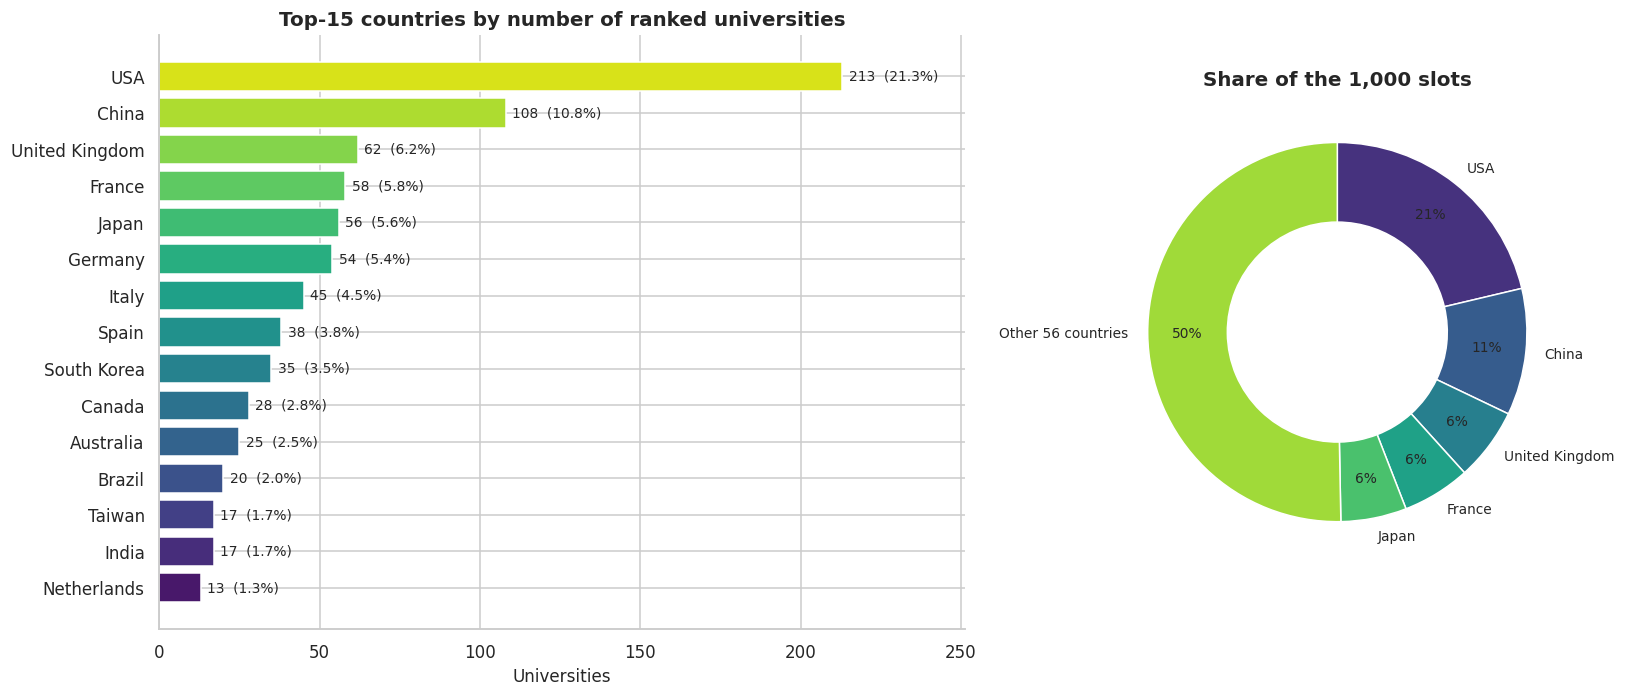

In [38]:
counts = d["Location"].value_counts()
fig = plt.figure(figsize=(15, 6.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.7, 1])
ax1 = fig.add_subplot(gs[0])
top15 = counts.head(15)[::-1]
bars = ax1.barh(top15.index, top15.values, color=sns.color_palette("viridis", 15))
for b, v in zip(bars, top15.values):
    ax1.text(v + 2, b.get_y() + b.get_height()/2, f"{v}  ({v/10:.1f}%)", va="center", fontsize=9)
ax1.set_title("Top-15 countries by number of ranked universities"); ax1.set_xlabel("Universities")
ax1.set_xlim(0, top15.max() * 1.18)

ax2 = fig.add_subplot(gs[1])
top5 = counts.head(5); other = counts.iloc[5:].sum()
vals = list(top5.values) + [other]; labs = list(top5.index) + [f"Other {len(counts)-5} countries"]
ax2.pie(vals, labels=labs, startangle=90, counterclock=False, colors=sns.color_palette("viridis", 6),
        wedgeprops=dict(width=.42, edgecolor="white"), autopct=lambda p: f"{p:.0f}%", pctdistance=.79, textprops=dict(fontsize=9))
ax2.set_title("Share of the 1,000 slots")
plt.tight_layout(); plt.show()

**Insights.** The list is extremely **concentrated**: the USA alone holds 213 of the 1,000 slots (21 %), followed by China (108) and the UK (62). The top five countries account for about half of the list, while 40-plus countries appear with fewer than ten universities each. Any country-level statistic (means, boxplots) must therefore be limited to countries with enough observations — we use ≥ 10 universities below.

### 7.4 How good are the universities of each country?

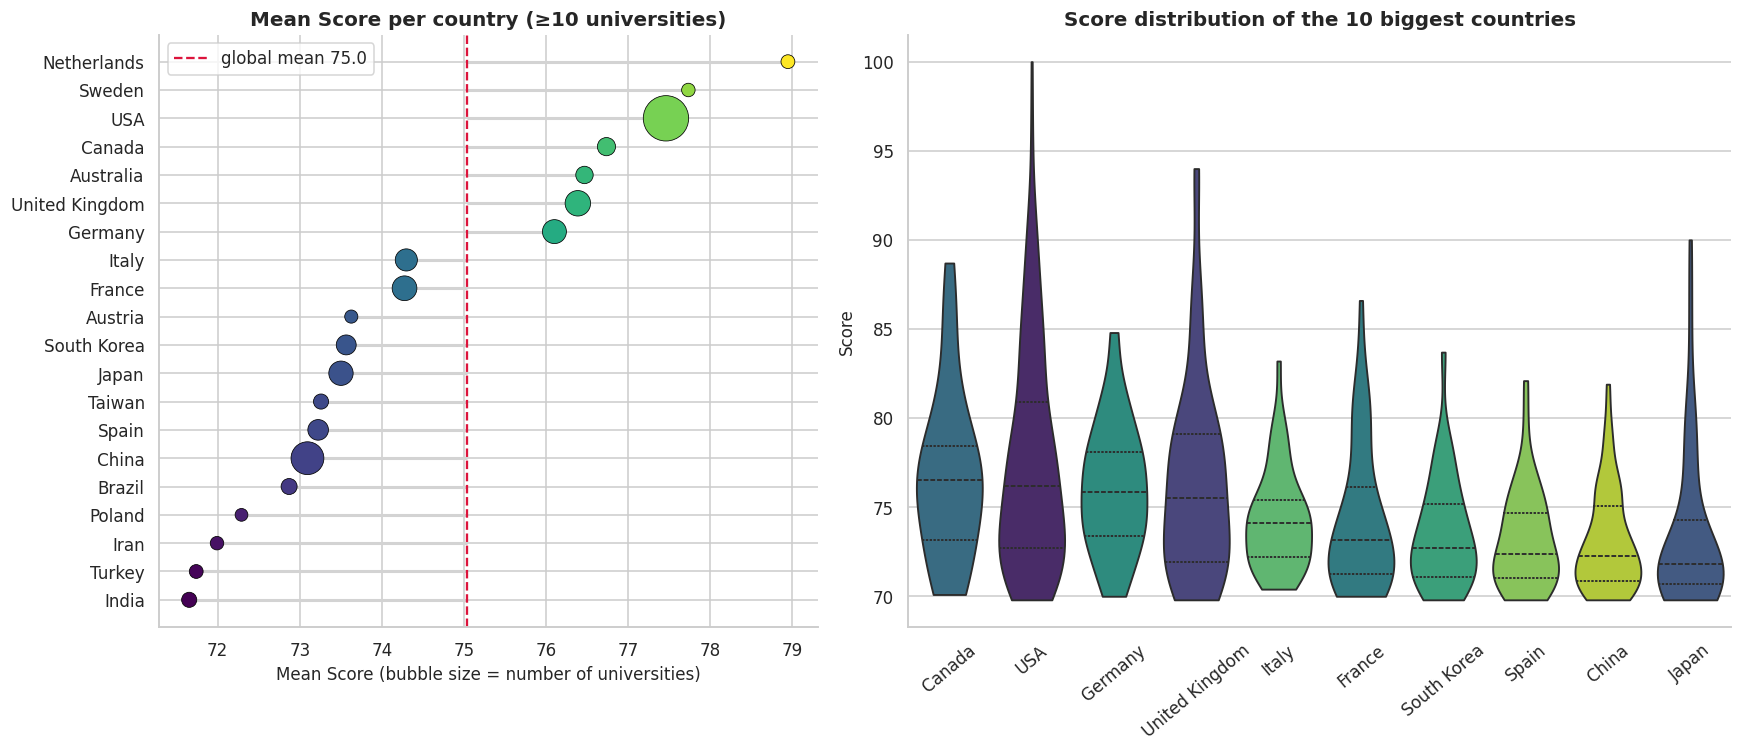

,n,mean,median,top100
Location,,,,
Netherlands,13,78.95,80.40,3
Sweden,12,77.73,78.20,3
USA,213,77.46,76.20,51
Canada,28,76.74,76.50,4
Australia,25,76.47,75.10,4
United Kingdom,62,76.39,75.50,8
Germany,54,76.10,75.85,3
Italy,45,74.30,74.10,1


In [39]:
agg = d.groupby("Location").agg(n=("Score", "size"), mean=("Score", "mean"), median=("Score", "median"),
                                top100=("World Rank", lambda s: (s <= 100).sum())).query("n >= 10").sort_values("mean")
overall = d["Score"].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.hlines(agg.index, overall, agg["mean"], color="lightgrey", lw=2)
sc = ax.scatter(agg["mean"], agg.index, s=agg["n"] * 4 + 30, c=agg["mean"], cmap="viridis", edgecolor="black", linewidth=.5, zorder=3)
ax.axvline(overall, color="crimson", ls="--", label=f"global mean {overall:.1f}")
ax.set_xlabel("Mean Score (bubble size = number of universities)"); ax.legend()
ax.set_title("Mean Score per country (≥10 universities)")

top10 = d["Location"].value_counts().head(10).index
order = d[d["Location"].isin(top10)].groupby("Location")["Score"].median().sort_values(ascending=False).index
sns.violinplot(data=d[d["Location"].isin(top10)], x="Location", y="Score", order=order, hue="Location",
               palette="viridis", inner="quart", cut=0, legend=False, ax=axes[1])
axes[1].set_title("Score distribution of the 10 biggest countries"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()
agg.sort_values("mean", ascending=False).round(2).head(8)

**Insights.** Among countries with ≥ 10 universities, the **Netherlands (78.9) and Sweden (77.7)** post the highest *average* scores (few but strong universities), followed by the **USA (77.5)**, whose mean is lifted by its elite top. (Switzerland, with 9 universities, just misses the filter but averages 79.9.) **China, Brazil, India, Spain and Taiwan** sit below the global mean: they contribute many universities, but most land in the lower half of the list. The violins show *why*: the USA has a very long upper tail (its elite institutions) while most Asian and Southern-European systems are concentrated just above the cut-off score of ≈ 70.

### 7.5 Who populates each ranking tier?

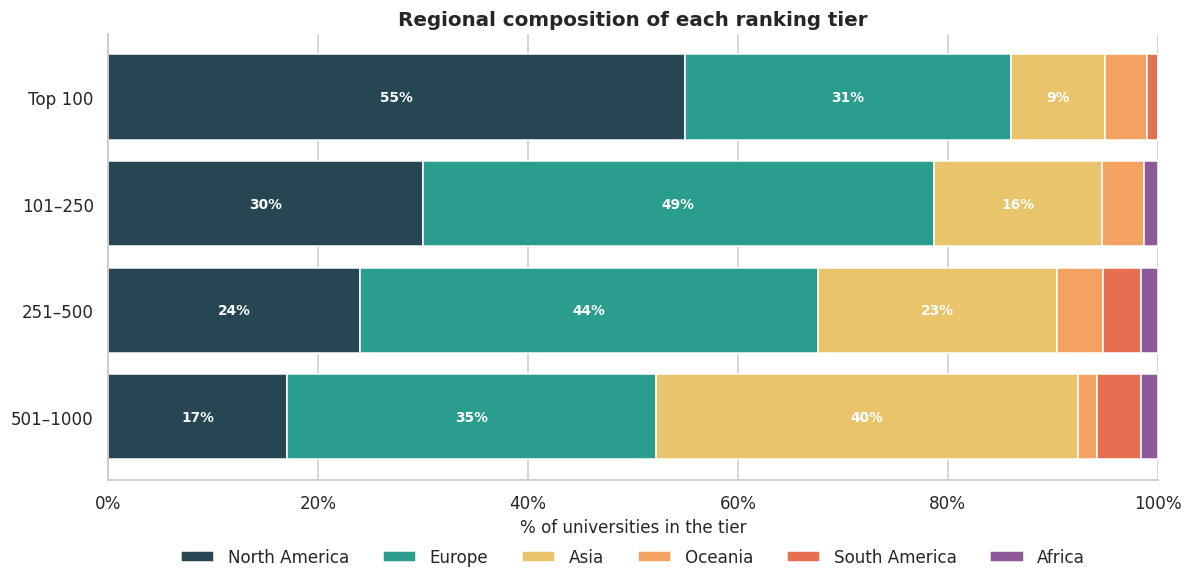

Region,Africa,Asia,Europe,North America,Oceania,South America
Rank band,,,,,,
Top 100,0,9,31,55,4,1
101–250,2,24,73,45,6,0
251–500,4,57,109,60,11,9
501–1000,8,201,176,85,9,21


In [40]:
ct = pd.crosstab(d["Rank band"], d["Region"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
ct_pct = ct_pct[list(REGION_COLORS)]
fig, ax = plt.subplots(figsize=(11, 5.5))
left = np.zeros(len(ct_pct))
for reg in ct_pct.columns:
    ax.barh(ct_pct.index.astype(str), ct_pct[reg], left=left, color=REGION_COLORS[reg], label=reg, edgecolor="white")
    for i, (v, l) in enumerate(zip(ct_pct[reg], left)):
        if v >= 6: ax.text(l + v/2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += ct_pct[reg].values
ax.invert_yaxis(); ax.set_xlabel("% of universities in the tier"); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(.5, -.12), frameon=False)
ax.set_title("Regional composition of each ranking tier")
plt.tight_layout(); plt.show()
ct

**Insights.** **North America** supplies 55 % of the top 100 and its share falls steadily in the lower tiers (30 % → 24 % → 17 %). **Asia** shows the opposite pattern: 9 % of the top 100, rising to 16 %, 23 % and finally **40 % of the 501–1000 tier**. **Europe** is the largest contributor in every tier below the top 100 (31 % → 49 % → 44 % → 35 %). Africa and South America barely register in any tier.

### 7.6 Which indicators drive the final score? (correlation)

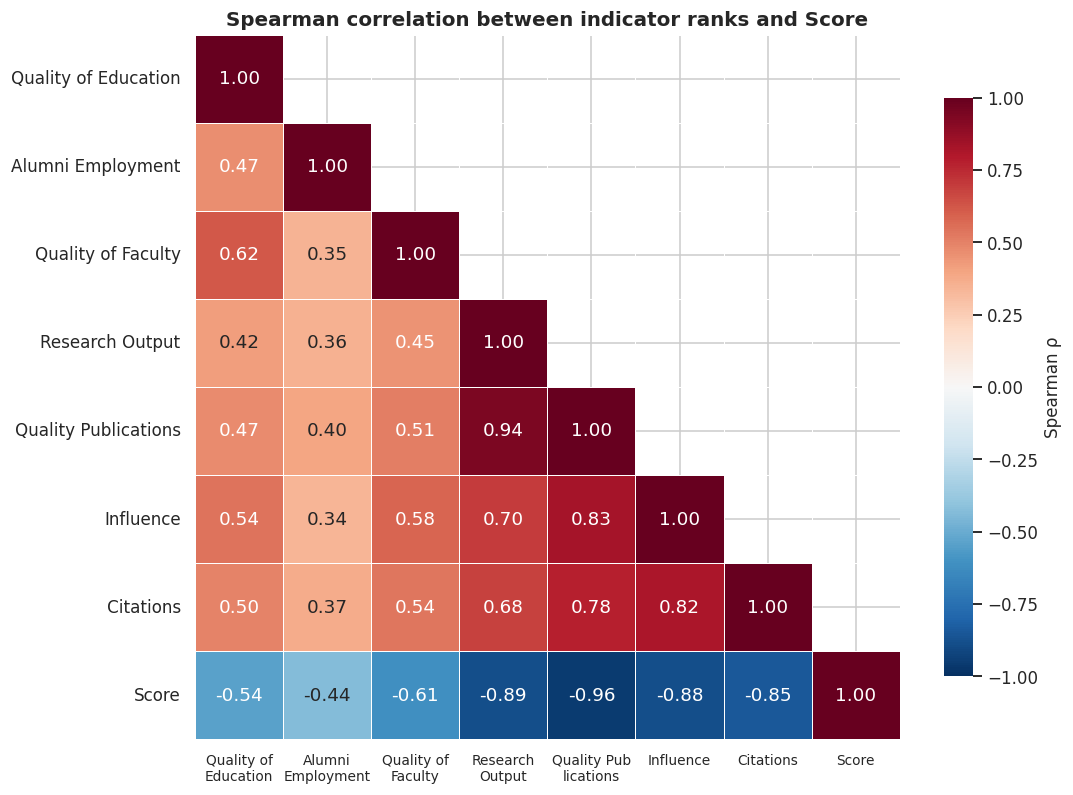

In [41]:
cols = IND + ["Score"]
corr = d[cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.6, square=True, cbar_kws={"shrink": .75, "label": "Spearman ρ"}, ax=ax)
ax.set_xticklabels([textwrap.fill(c, 11) for c in cols], rotation=0, fontsize=9)
ax.set_title("Spearman correlation between indicator ranks and Score")
plt.tight_layout(); plt.show()

**How to read it.** All indicators are *ranks* (small = good) while `Score` is "big = good", so correlations with `Score` are **negative by construction**; what matters is their magnitude.

**Insights.**
* `Quality Publications` is almost a perfect proxy of the final score (|ρ| ≈ 0.96), followed by `Research Output` (0.89), `Influence` (0.88) and `Citations` (0.85) — the **research block dominates** the ranking.
* The four research indicators are **highly inter-correlated** (up to 0.94 between `Research Output` and `Quality Publications`) → heavy multicollinearity; they carry overlapping information.
* `Quality of Education` and `Quality of Faculty` correlate with each other (≈ 0.6) because both come from the same award data.
* `Alumni Employment` is the **most independent** indicator (ρ ≈ 0.34–0.47 with the other indicators) — it adds information that the others do not.

### 7.7 Pairwise relationships of the research block

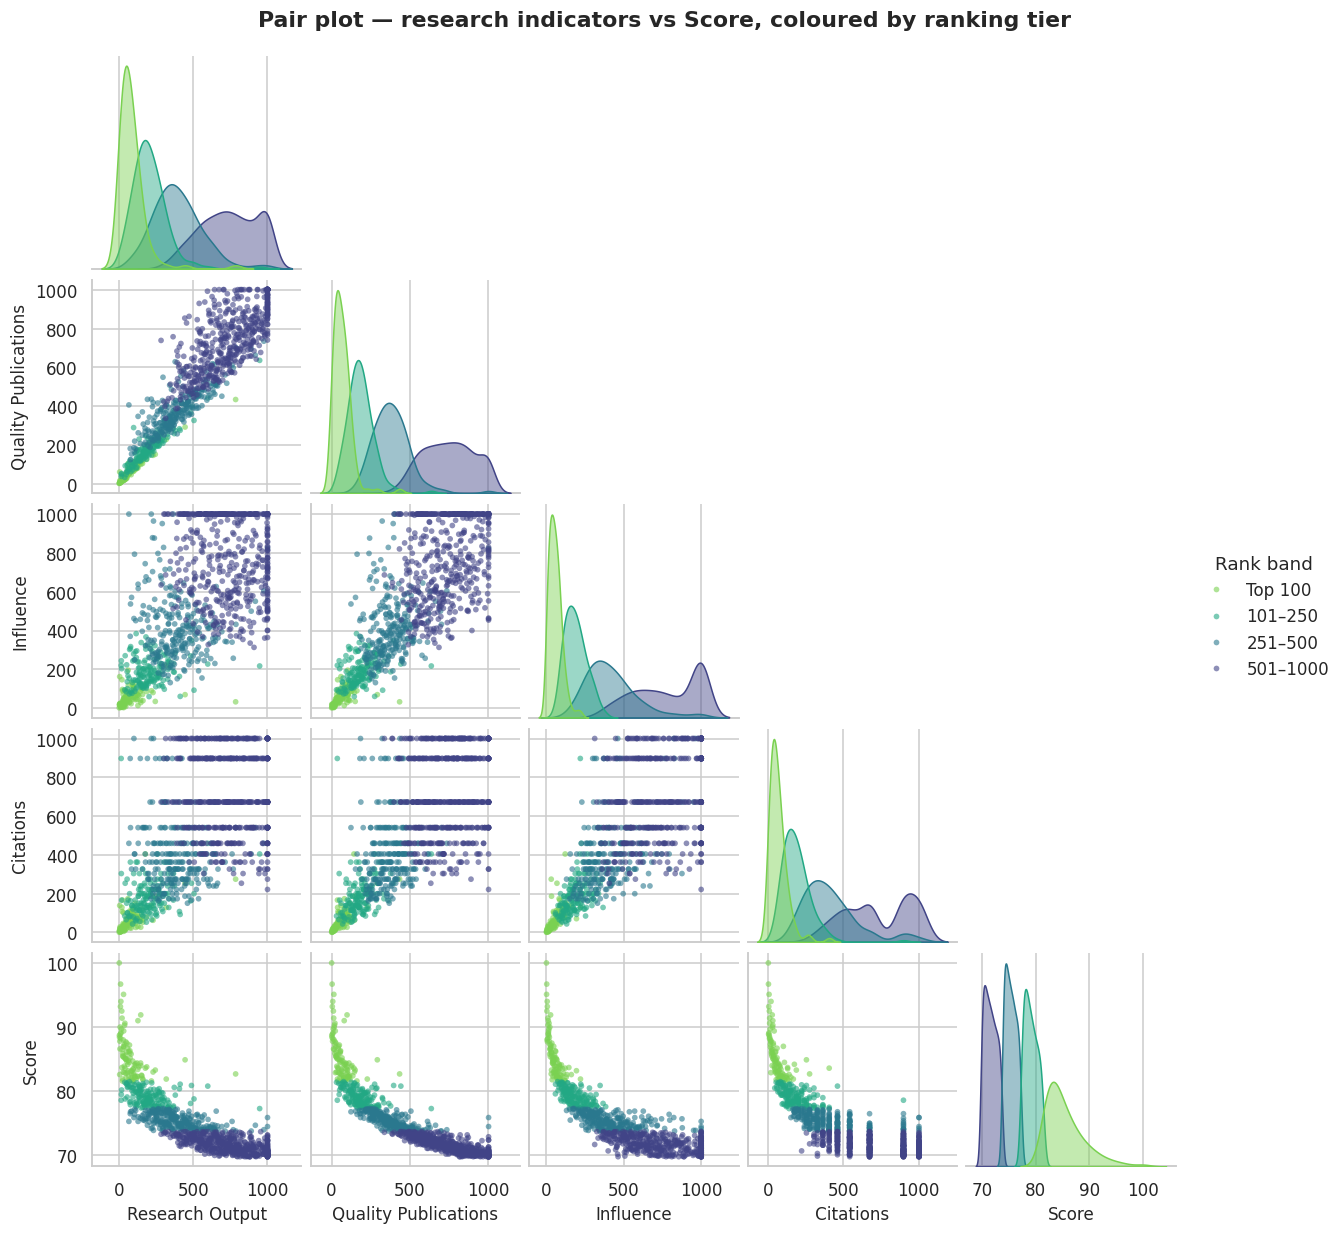

In [42]:
vars_ = ["Research Output", "Quality Publications", "Influence", "Citations", "Score"]
g = sns.pairplot(d, vars=vars_, hue="Rank band", palette="viridis_r", corner=True,
                 plot_kws=dict(s=14, alpha=.6, linewidth=0), diag_kws=dict(common_norm=False, fill=True, alpha=.45),
                 height=2.2)
g.figure.suptitle("Pair plot — research indicators vs Score, coloured by ranking tier", y=1.02, fontweight="bold")
plt.show()

**Insights.** The clouds along the diagonal-like bands confirm the strong monotonic dependence between research indicators. Three structural features are visible: (1) the **vertical/horizontal stripes** at the far end of each axis are the censored `1001` values; (2) `Citations` forms visible **horizontal/vertical bands** — the tied-rank plateaus found in Section 6.2; (3) the colour layers are almost perfectly stacked: the top-100 tier (yellow) sits in the bottom-left of every rank-vs-rank panel and in the top of every `Score` panel, so the research block alone is enough to separate the tiers.

### 7.8 Unranked universities by country (informative missingness, visualised)

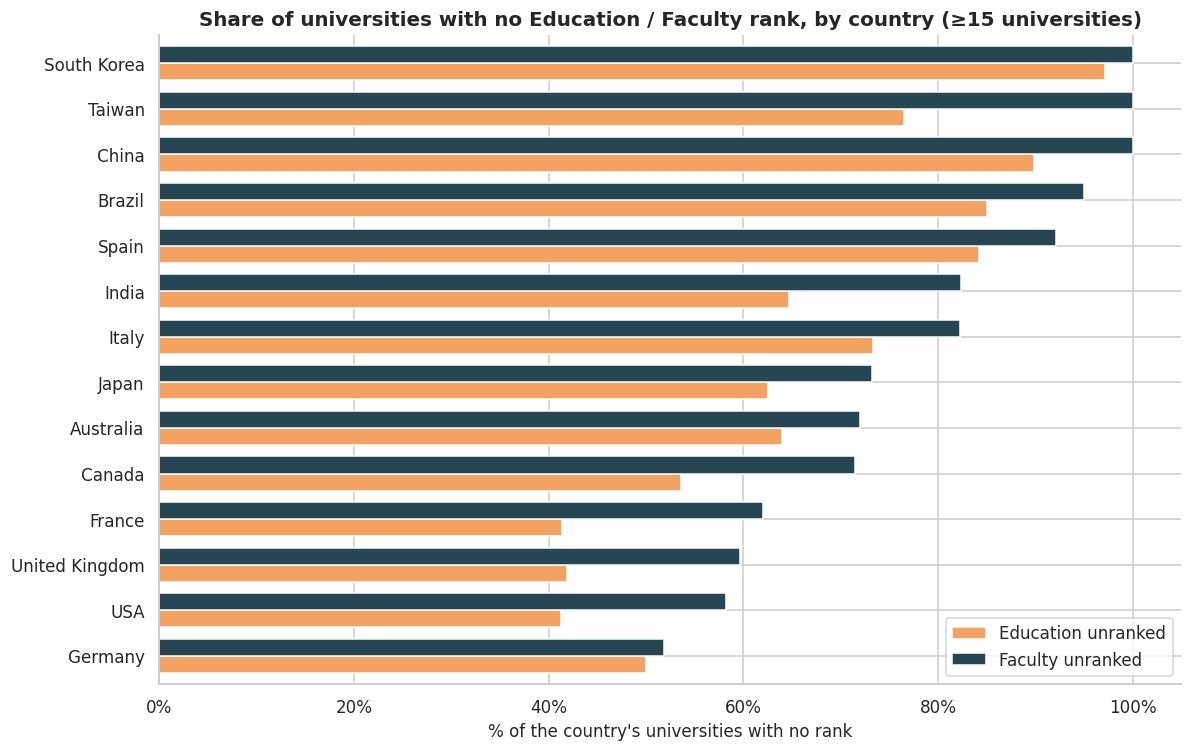

In [43]:
big = d["Location"].value_counts()[lambda s: s >= 15].index
u = (d[d["Location"].isin(big)]
     .groupby("Location")[["Quality of Education_unranked", "Quality of Faculty_unranked"]].mean() * 100)
u.columns = ["Education unranked", "Faculty unranked"]
u = u.sort_values("Faculty unranked")
ax = u.plot.barh(figsize=(11, 7), color=["#f4a261", "#264653"], width=.75, edgecolor="white")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel("% of the country's universities with no rank")
ax.set_ylabel(""); ax.set_title("Share of universities with no Education / Faculty rank, by country (≥15 universities)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Insights.** The two award-based indicators separate countries sharply. In the **USA, UK and France** only about 41–42 % of universities are unranked on `Quality of Education`, whereas in **Spain, Brazil, China and South Korea** it is 84–97 % (Italy 73 %). For `Quality of Faculty` the contrast is even starker: **100 % of Chinese, Korean and Taiwanese universities are unranked**, versus 58–62 % in the USA, UK and France. The dash is thus not only a "weak university" marker; it is also a strong **geographic / historical signal** (long-established Western institutions have had more time to produce award-winning alumni and staff). Region-aware models should include these flags.

### 7.9 Density of two research indicators

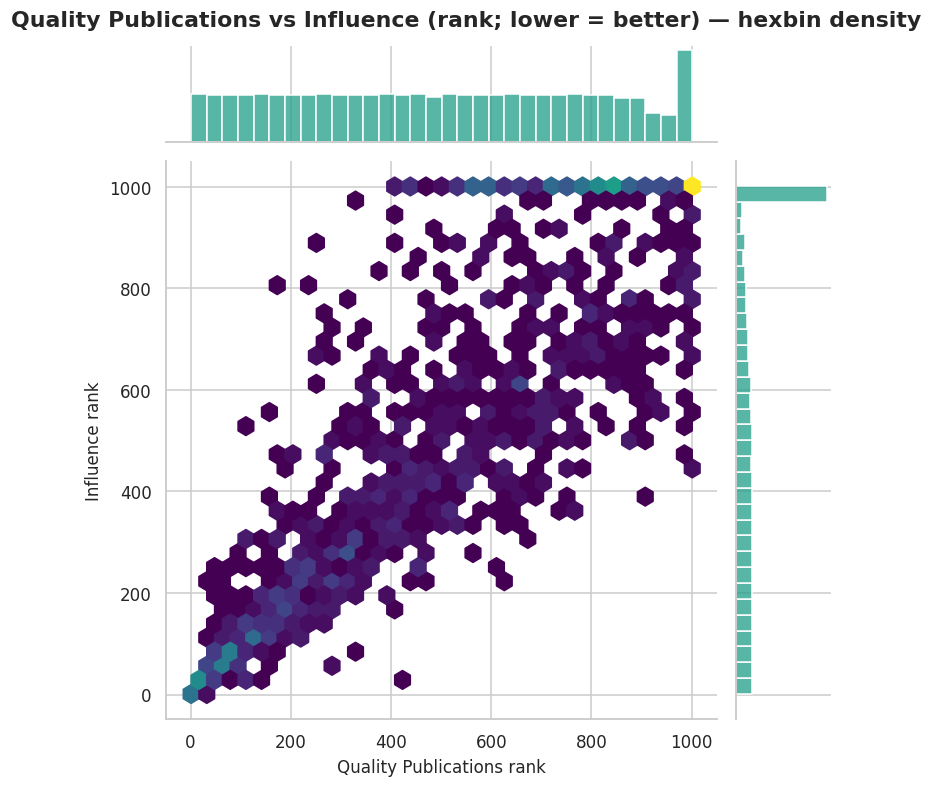

In [44]:
g = sns.jointplot(data=d, x="Quality Publications", y="Influence", kind="hex", gridsize=32, cmap="viridis",
                  marginal_kws=dict(bins=32, color=PALETTE[4]), height=7, mincnt=1)
g.figure.suptitle("Quality Publications vs Influence (rank; lower = better) — hexbin density", y=1.02, fontweight="bold")
g.ax_joint.set_xlabel("Quality Publications rank"); g.ax_joint.set_ylabel("Influence rank")
plt.show()

**Insights.** The hexbin removes over-plotting and exposes the true density: universities are strung along a **diagonal ridge** (a good publication rank usually comes with a good influence rank; ρ ≈ 0.83) and **pile up in the top-right corner** — the censored `> 1000` universities. The marginal histograms are both strongly right-skewed: only a few hundred institutions have good (small) ranks, while the majority crowd the high-rank end.

### 7.10 Profile of the top-5 universities (radar chart)

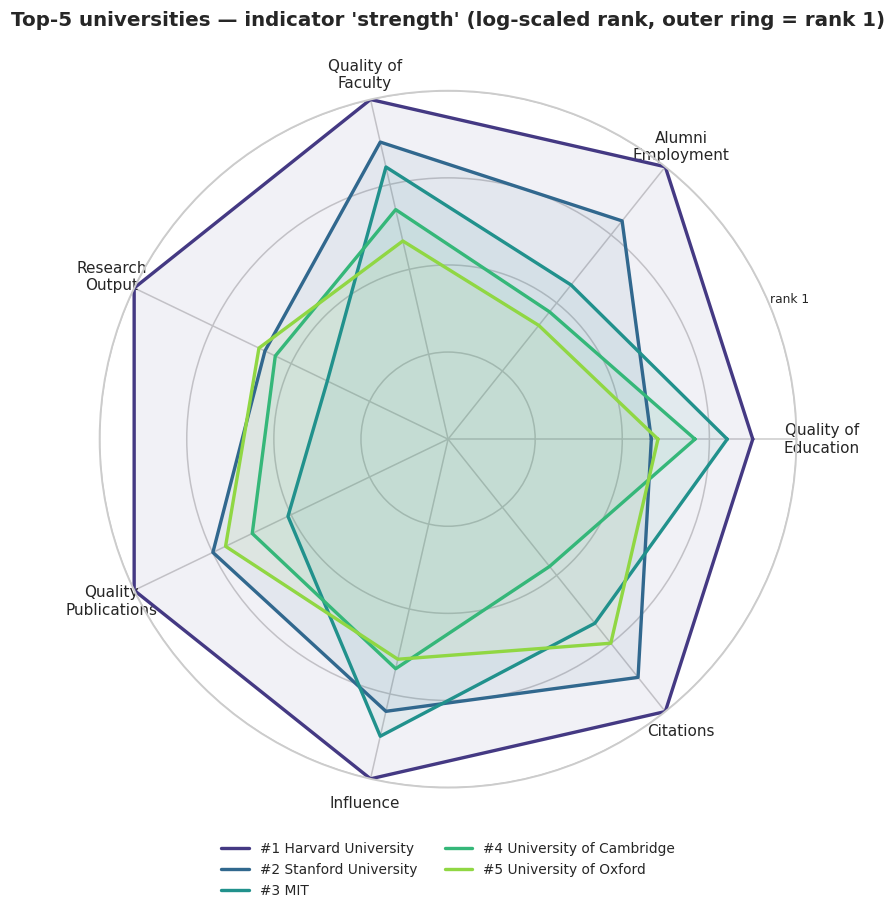

In [45]:
top5 = d.nsmallest(5, "World Rank")
angles = np.linspace(0, 2*np.pi, len(IND), endpoint=False).tolist(); angles += angles[:1]
fig, ax = plt.subplots(figsize=(8.5, 8.5), subplot_kw=dict(polar=True))
for (_, r), col in zip(top5.iterrows(), sns.color_palette("viridis", 5)):
    vals = strength(r[IND].astype(float).values).tolist(); vals += vals[:1]
    name = r["Institution"].replace("Massachusetts Institute of Technology", "MIT")
    ax.plot(angles, vals, color=col, lw=2.2, label=f"#{r['World Rank']} {name}")
    ax.fill(angles, vals, color=col, alpha=.07)
ax.set_xticks(angles[:-1]); ax.set_xticklabels([textwrap.fill(c, 12) for c in IND], fontsize=10)
ax.set_ylim(.2, 1.0); ax.set_yticks([.4, .6, .8, 1.0]); ax.set_yticklabels(["", "", "", "rank 1"], fontsize=8)
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.06), ncol=2, frameon=False, fontsize=9)
ax.set_title("Top-5 universities — indicator 'strength' (log-scaled rank, outer ring = rank 1)", y=1.08)
plt.tight_layout(); plt.show()

**Insights.** The five best universities are strong on **every** axis (all polygons hug the outer ring), but their *shapes* differ. **Harvard** is ranked 1st on six of the seven indicators (2nd on Education). **Stanford** is balanced (ranks 2–10). **MIT** has the most dented profile — 30th in Research Output but 2nd in Influence. **Cambridge** and **Oxford** are weakest on Alumni Employment (19th and 25th), and Cambridge also on Citations (19th). The log-scaled strength makes small rank gaps among the elite visible; with raw ranks all five polygons would collapse into one blob near the outer edge.

### 7.11 Regional score distributions

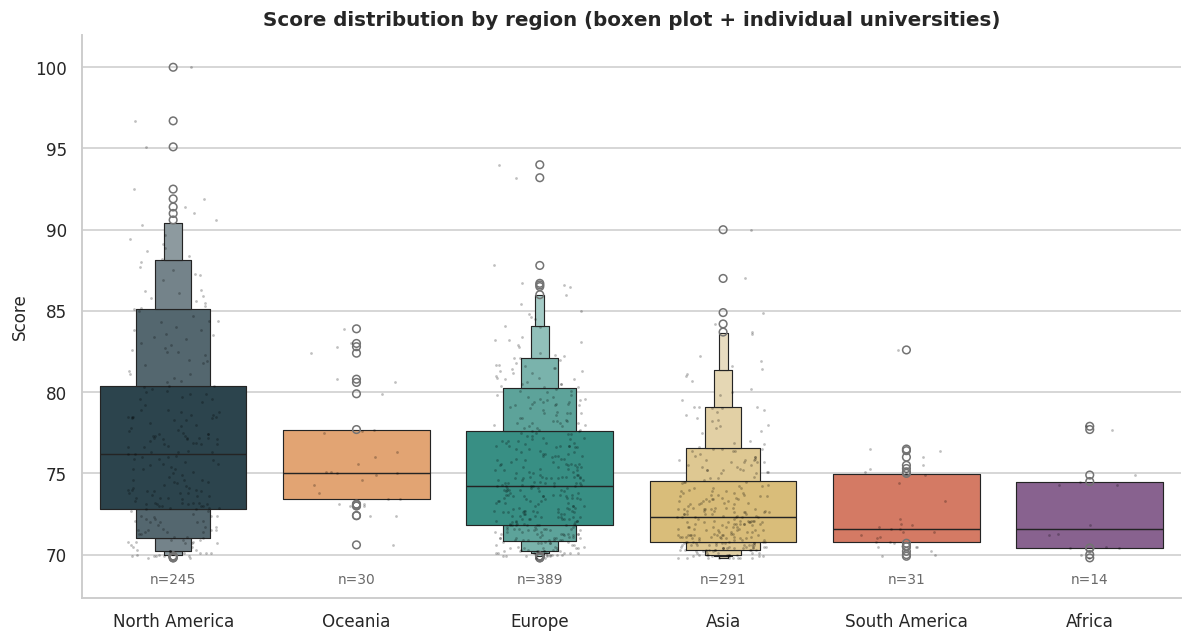

               count  median   mean    max
Region                                    
North America    245   76.20  77.31  100.0
Oceania           30   75.05  76.21   83.9
Europe           389   74.20  75.12   94.0
Asia             291   72.30  73.24   90.0
South America     31   71.60  72.77   82.6
Africa            14   71.55  72.79   77.9


In [46]:
order = d.groupby("Region")["Score"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxenplot(data=d, x="Region", y="Score", order=order, hue="Region", palette=REGION_COLORS, legend=False, ax=ax)
sns.stripplot(data=d, x="Region", y="Score", order=order, color="black", size=1.8, alpha=.25, jitter=.25, ax=ax)
for i, reg in enumerate(order):
    ax.text(i, d["Score"].min() - 1.6, f"n={int((d['Region'] == reg).sum())}", ha="center", fontsize=9, color="dimgray")
ax.set_ylim(d["Score"].min() - 2.5, d["Score"].max() + 2); ax.set_xlabel("")
ax.set_title("Score distribution by region (boxen plot + individual universities)")
plt.tight_layout(); plt.show()
print(d.groupby("Region")["Score"].agg(["count", "median", "mean", "max"]).round(2).loc[order])

**Insights.** All regions share the same floor (≈ 70, the cut-off of the list) — what differs is the **height of the upper tail**. **North America** has the highest median (76.2) and the tallest tail (max 100); **Europe** follows (median 74.2, max 94.0). **Oceania** is compact (median 75.1, no university above 84). **Asia** has 291 universities but a low median (72.3) and a thin top end — the University of Tokyo (90.0) is the clear exception. Africa and South America each have too few universities for strong conclusions, which the `n=` labels make explicit.

### 7.12 Heat-map of the top-25 universities

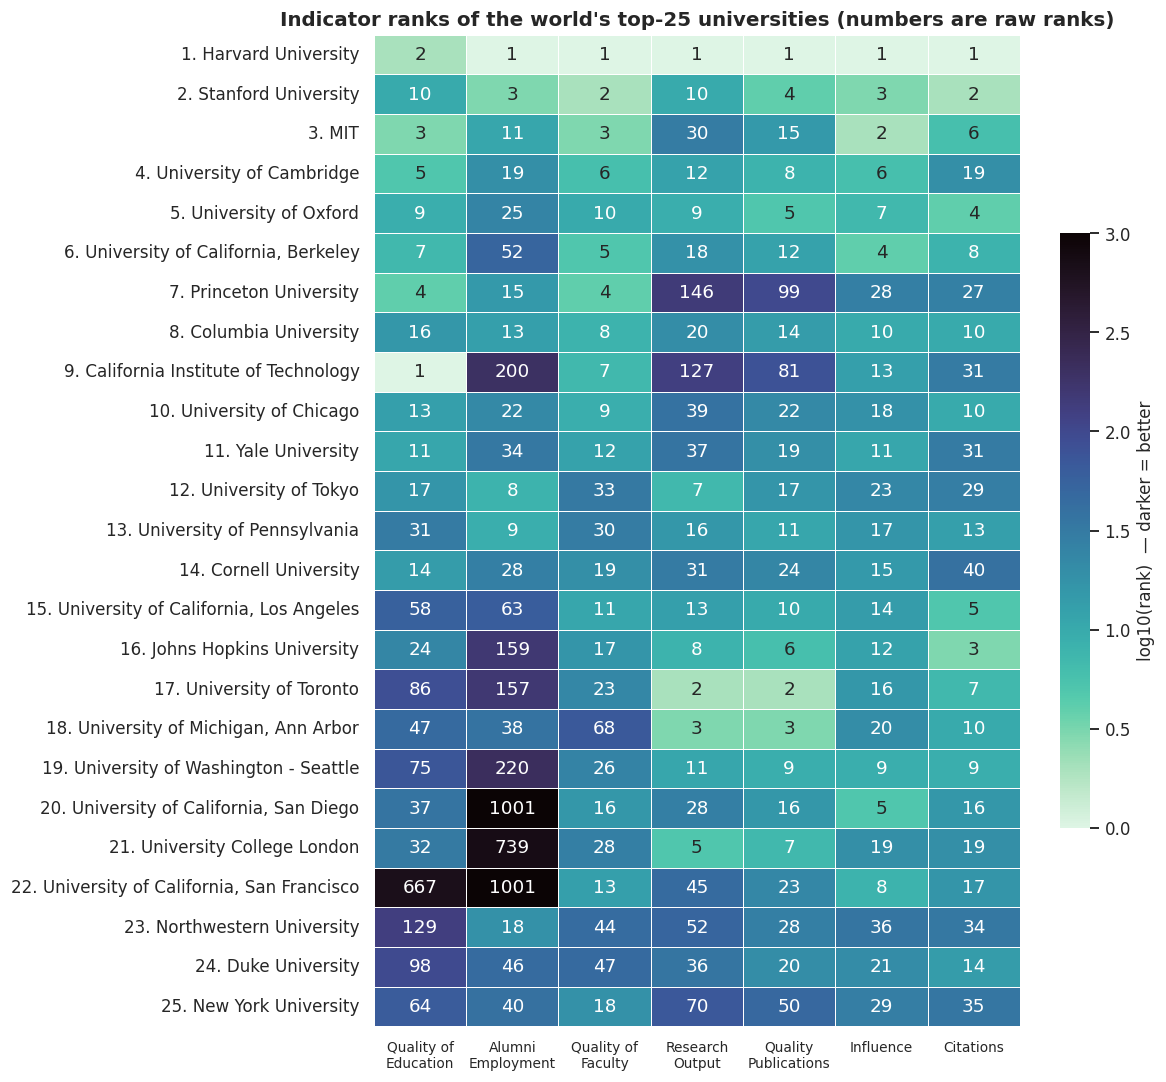

In [47]:
top25 = d.nsmallest(25, "World Rank").set_index("Institution")[IND]
top25.index = [f"{i+1}. " + n.replace("Massachusetts Institute of Technology", "MIT") for i, n in enumerate(top25.index)]
fig, ax = plt.subplots(figsize=(11, 10))
sns.heatmap(np.log10(top25), annot=top25, fmt="d", cmap="mako_r", linewidths=.5, linecolor="white",
            cbar_kws={"label": "log10(rank)  — darker = better", "shrink": .6}, ax=ax)
ax.set_xticklabels([textwrap.fill(c, 12) for c in IND], rotation=0, fontsize=9)
ax.set_title("Indicator ranks of the world's top-25 universities (numbers are raw ranks)")
plt.tight_layout(); plt.show()

**Insights.** The list is American-dominated even at the very top: **20 of the 25** universities are from the USA (3 from the UK, 1 each from Canada and Japan). Still, **no university is best everywhere**: the darkest (best) cells shift from column to column. Notice also that a few top-25 institutions have comparatively weak `Alumni Employment` values (large numbers, lighter cells) — the indicator that is least correlated with the others (Section 7.6). The colour is based on `log10(rank)`, so the difference between rank 1 and 10 is visually as important as between 100 and 1000.

### 7.13 Country bubble chart: size, quality and elite presence

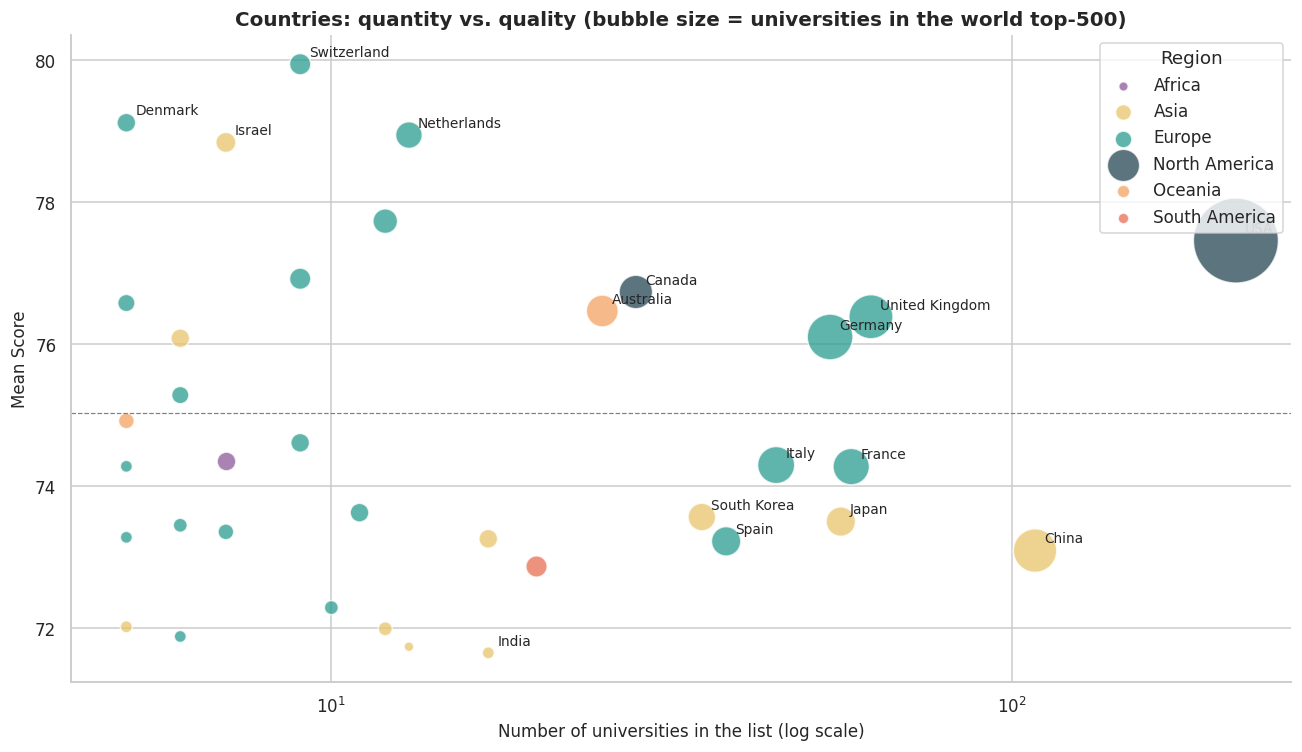

In [48]:
cb = d.groupby("Location").agg(n=("Score", "size"), mean=("Score", "mean"),
                               top500=("World Rank", lambda s: (s <= 500).sum()), Region=("Region", "first")).query("n >= 5")
fig, ax = plt.subplots(figsize=(12, 7))
for reg, sub in cb.groupby("Region"):
    ax.scatter(sub["n"], sub["mean"], s=sub["top500"] * 22 + 40, color=REGION_COLORS[reg], alpha=.75,
               edgecolor="white", linewidth=1, label=reg)
for loc, r in cb.iterrows():
    if r["n"] >= 25 or r["mean"] >= 78.5 or r["n"] >= 15 and r["mean"] <= 72:
        ax.annotate(loc, (r["n"], r["mean"]), textcoords="offset points", xytext=(6, 5), fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Number of universities in the list (log scale)")
ax.set_ylabel("Mean Score"); ax.axhline(d["Score"].mean(), color="grey", ls="--", lw=.8)
leg = ax.legend(title="Region", loc="upper right", markerscale=.5)
ax.set_title("Countries: quantity vs. quality (bubble size = universities in the world top-500)")
plt.tight_layout(); plt.show()

**Insights.** Quantity and quality are **not the same thing**. The USA is both large *and* high (big bubble, high on the y-axis); China is large but average (big in x, below the global mean); small research-intensive systems — Switzerland (79.9), Denmark (79.1), the Netherlands (78.9), Sweden (77.7) — appear in the upper-left with high averages but small bubbles. China shows the opposite extreme: 108 universities on the list, yet only 2 in the top 100.

### 7.14 Comparing the seven indicators on one scale

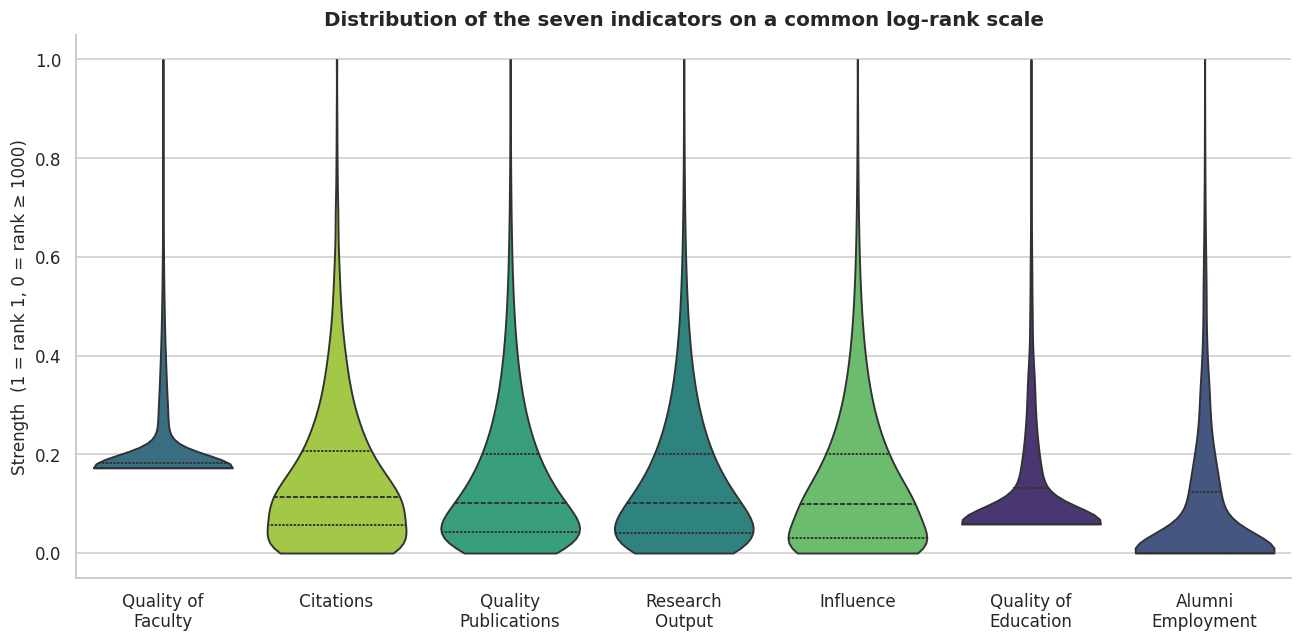

In [49]:
long = d[IND].apply(strength).melt(var_name="Indicator", value_name="Strength")
order = long.groupby("Indicator")["Strength"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 6))
sns.violinplot(data=long, x="Indicator", y="Strength", order=order, hue="Indicator", palette="viridis",
               inner="quart", cut=0, density_norm="width", legend=False, ax=ax)
ax.set_xticklabels([textwrap.fill(t.get_text(), 12) for t in ax.get_xticklabels()])
ax.set_ylabel("Strength  (1 = rank 1, 0 = rank ≥ 1000)"); ax.set_xlabel("")
ax.set_title("Distribution of the seven indicators on a common log-rank scale")
plt.tight_layout(); plt.show()

**Insights.** On a common scale the indicators fall into two families. The **research block** (`Research Output`, `Quality Publications`, `Influence`, `Citations`) is spread over the whole range with most mass in the mid-range — most universities can compete on these. The **award/employment block** (`Quality of Faculty`, `Quality of Education`, `Alumni Employment`) is **bimodal**: a thin group of strong institutions and a massive spike near the bottom (strength ≈ 0–0.2), which is exactly the unranked/censored pile created by our imputation (Section 4). This explains why these three indicators discriminate poorly among the bottom 600 universities.

### 7.15 World map: where are the universities, and how good are they?

Two choropleth maps built from [Natural Earth](https://www.naturalearthdata.com/) country outlines (downloaded once and cached next to the notebook; **internet is needed the first time only**). Matching is done on country names; the three city-states missing from the 110 m outlines (Hong Kong, Macau, Singapore) are drawn as dots.

Countries matched to a shape: 58 | drawn as dots: ['Hong Kong', 'Macau', 'Singapore'] | unmatched: []


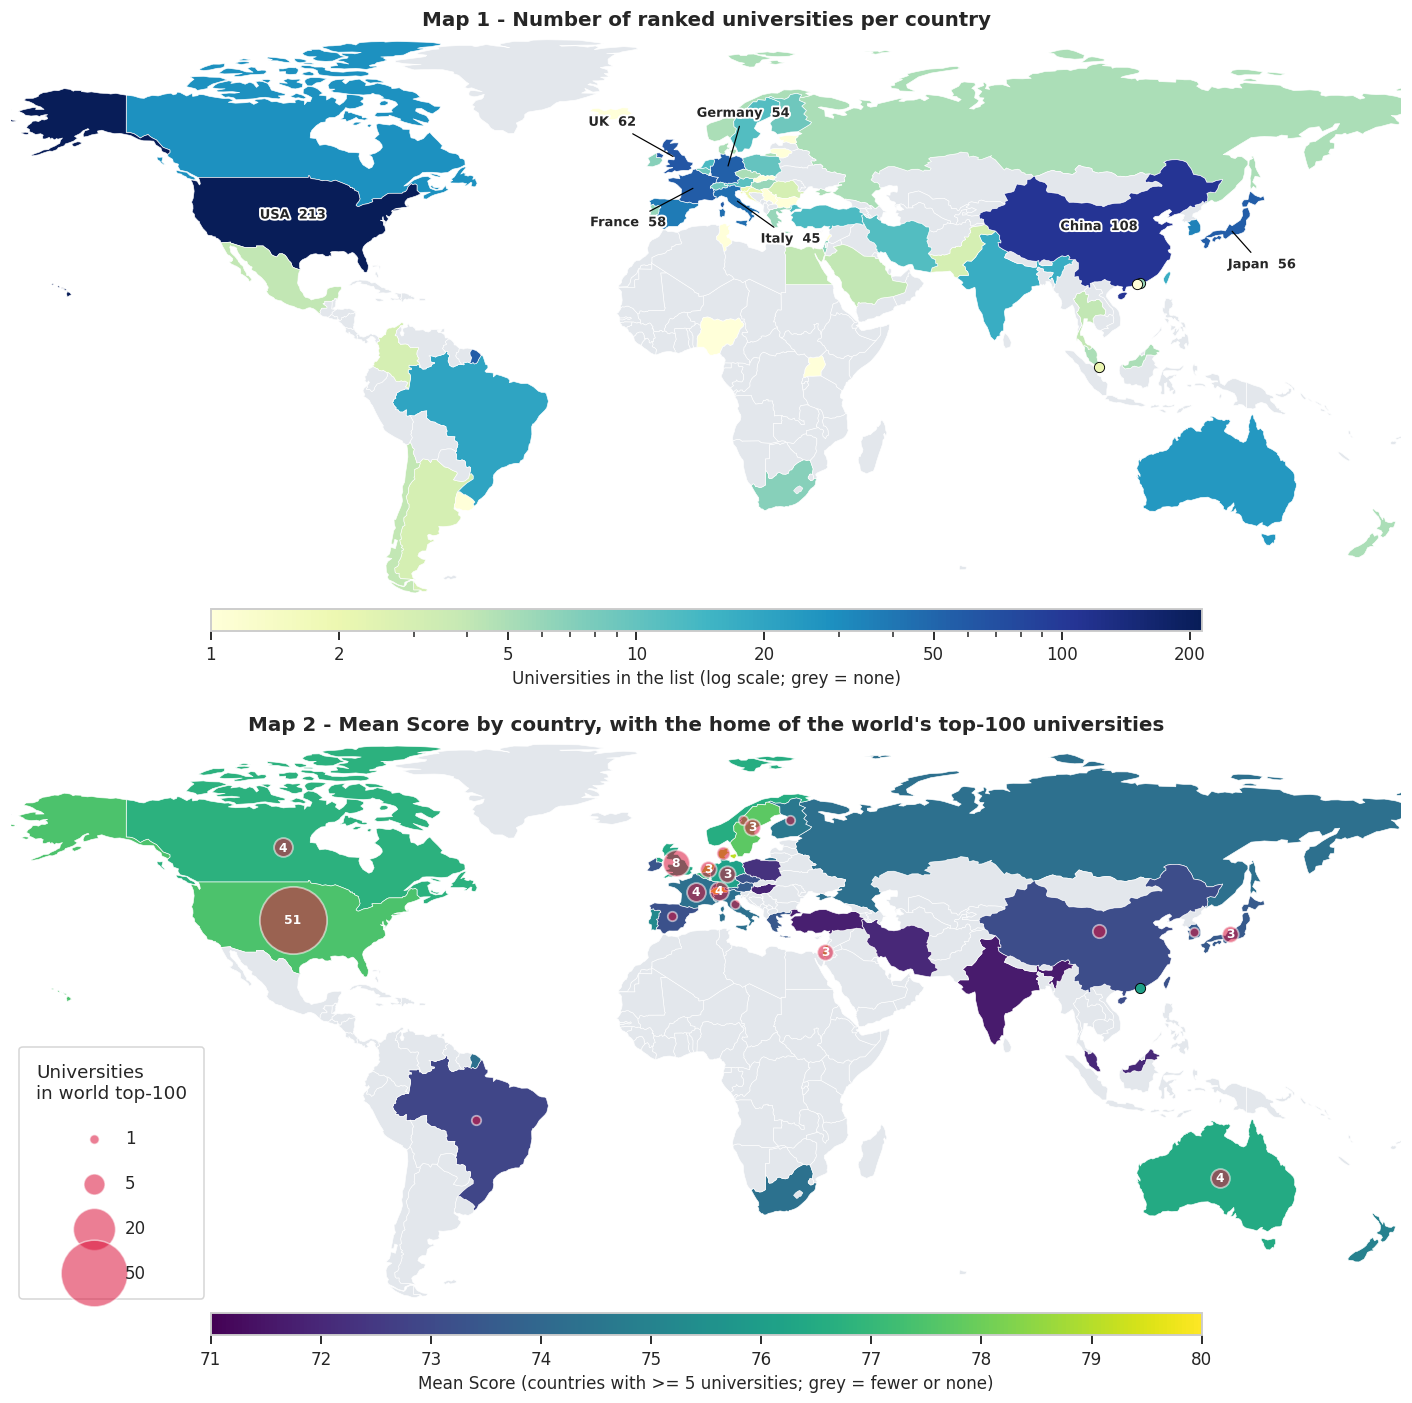

{'Switzerland': 79.94, 'Denmark': 79.12, 'Netherlands': 78.95, 'Israel': 78.84, 'Sweden': 77.73}
{'India': 71.65, 'Turkey': 71.74, 'Hungary': 71.88, 'Iran': 71.99, 'Malaysia': 72.02}


In [50]:
import json, urllib.request
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.colors import LogNorm, Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe

GEO_FILE = Path("ne_110m_admin_0_countries.geojson")
GEO_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
MAP_OK = True
try:
    if not GEO_FILE.exists():
        urllib.request.urlretrieve(GEO_URL, GEO_FILE)
    world = json.load(open(GEO_FILE, encoding="utf-8"))
except Exception as e:
    MAP_OK = False
    print("Map skipped - could not download country outlines:", e)

if MAP_OK:
    ALIAS = {"USA": "United States of America", "Slovak Republic": "Slovakia"}
    SMALL = {"Hong Kong": (114.17, 22.32), "Macau": (113.54, 22.20), "Singapore": (103.82, 1.35)}  # not in 110 m shapes

    feat_by_name = {}
    for f in world["features"]:
        for k in ("NAME", "ADMIN", "NAME_LONG"):
            feat_by_name[f["properties"][k]] = f

    cs = d.groupby("Location").agg(n=("Score", "size"), mean=("Score", "mean"),
                                   top100=("World Rank", lambda x: (x <= 100).sum()))
    loc_feat = {loc: feat_by_name[ALIAS.get(loc, loc)] for loc in cs.index if ALIAS.get(loc, loc) in feat_by_name}
    unmatched = [l for l in cs.index if l not in loc_feat and l not in SMALL]
    print(f"Countries matched to a shape: {len(loc_feat)} | drawn as dots: {list(SMALL)} | unmatched: {unmatched}")
    assert not unmatched, "add an alias for these countries"

    def get_rings(geom):
        polys = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        return [np.array(p[0]) for p in polys]                        # exterior rings only

    def ring_centroid(r):
        x, y = r[:, 0], r[:, 1]; a = x[:-1] * y[1:] - x[1:] * y[:-1]; A = a.sum() / 2
        return ((x[:-1] + x[1:]) * a).sum() / (6 * A), ((y[:-1] + y[1:]) * a).sum() / (6 * A)

    def centroid(loc):
        if loc in SMALL: return SMALL[loc]
        biggest = max(get_rings(loc_feat[loc]["geometry"]),
                      key=lambda r: abs(0.5 * np.sum(r[:-1, 0] * r[1:, 1] - r[1:, 0] * r[:-1, 1])))
        return ring_centroid(biggest)

    def draw_world(ax, values, cmap, norm, na_color="#e3e7ec"):
        # values: {country label: number}.  Countries without a value are grey.
        code_val = {loc_feat[l]["properties"]["ADM0_A3"]: v for l, v in values.items() if l in loc_feat}
        patches, colors = [], []
        for f in world["features"]:
            if f["properties"]["ADMIN"] == "Antarctica": continue
            v = code_val.get(f["properties"]["ADM0_A3"])
            col = cmap(norm(v)) if v is not None else na_color
            for r in get_rings(f["geometry"]):
                patches.append(MplPolygon(r, closed=True)); colors.append(col)
        ax.add_collection(PatchCollection(patches, facecolors=colors, edgecolors="white", linewidths=.4))
        for l, v in values.items():                                   # city-states as dots
            if l in SMALL:
                ax.scatter(*SMALL[l], s=45, color=cmap(norm(v)), edgecolor="black", linewidth=.6, zorder=4)
        ax.set_xlim(-170, 180); ax.set_ylim(-58, 85); ax.set_aspect("equal"); ax.axis("off")

    halo = [pe.withStroke(linewidth=2.5, foreground="white")]
    fig, axes = plt.subplots(2, 1, figsize=(13, 13))

    # ---- Map 1: number of universities (log colour scale)
    n_vals = cs["n"].to_dict()
    norm1 = LogNorm(vmin=1, vmax=cs["n"].max()); cmap1 = plt.get_cmap("YlGnBu")
    draw_world(axes[0], n_vals, cmap1, norm1)
    OFFSET = {"United Kingdom": (-16, 9), "France": (-17, -9), "Germany": (4, 14), "Italy": (14, -10), "Japan": (8, -9)}  # de-clutter Europe
    for loc in cs["n"].nlargest(7).index:
        x, y = centroid(loc); dx, dy = OFFSET.get(loc, (0, 0))
        axes[0].annotate(f"{loc.replace('United Kingdom', 'UK')}  {cs.loc[loc, 'n']}", (x, y), xytext=(x + dx, y + dy),
                         ha="center", va="center", fontsize=8.5, fontweight="bold", path_effects=halo, zorder=6,
                         arrowprops=dict(arrowstyle="-", lw=.8, color="black") if (dx or dy) else None)
    cb = fig.colorbar(ScalarMappable(norm=norm1, cmap=cmap1), ax=axes[0], orientation="horizontal",
                      fraction=.035, pad=.01, aspect=45, ticks=[1, 2, 5, 10, 20, 50, 100, 200])
    cb.ax.set_xticklabels([1, 2, 5, 10, 20, 50, 100, 200]); cb.set_label("Universities in the list (log scale; grey = none)")
    axes[0].set_title("Map 1 - Number of ranked universities per country")

    # ---- Map 2: mean Score (countries with >= 5 universities) + bubbles for top-100 universities
    MIN_N = 5
    m_vals = cs.loc[cs["n"] >= MIN_N, "mean"].to_dict()
    norm2 = Normalize(vmin=71, vmax=80); cmap2 = plt.get_cmap("viridis")
    draw_world(axes[1], m_vals, cmap2, norm2)
    top = cs[cs["top100"] > 0]
    for loc, r in top.iterrows():
        x, y = centroid(loc)
        axes[1].scatter(x, y, s=r["top100"] * 38, color="crimson", alpha=.55, edgecolor="white", linewidth=1.2, zorder=5)
        if r["top100"] >= 3:
            axes[1].text(x, y, int(r["top100"]), ha="center", va="center", fontsize=8, color="white", fontweight="bold", zorder=6)
    for k in (1, 5, 20, 50):                                           # size legend
        axes[1].scatter([], [], s=k * 38, color="crimson", alpha=.55, edgecolor="white", label=f"{k}")
    axes[1].legend(title="Universities\nin world top-100", loc="lower left", labelspacing=1.6, borderpad=1, frameon=True)
    cb2 = fig.colorbar(ScalarMappable(norm=norm2, cmap=cmap2), ax=axes[1], orientation="horizontal",
                       fraction=.035, pad=.01, aspect=45)
    cb2.set_label(f"Mean Score (countries with >= {MIN_N} universities; grey = fewer or none)")
    axes[1].set_title("Map 2 - Mean Score by country, with the home of the world's top-100 universities")
    plt.tight_layout(); plt.show()

    print(cs.loc[cs["n"] >= MIN_N, "mean"].sort_values(ascending=False).round(2).head(5).to_dict())
    print(cs.loc[cs["n"] >= MIN_N, "mean"].sort_values().round(2).head(5).to_dict())

**Insights.**

* **Map 1 - concentration and blank spots.** The list is dominated by a few dark spots: the **USA (213)**, **China (108)**, the **UK (62)**, **France (58)**, **Japan (56)** and **Germany (54)**. Large parts of the map are blank — only **five** African and five South-American countries appear at all, and Central Asia and most of the Middle East are missing. Of the 61 countries on the list, only 36 have five or more universities and 13 have just one, which is why the country-level statistics earlier were restricted to countries with enough observations.
* **Map 2 - quality is not the same as quantity.** Among countries with ≥ 5 universities, the highest mean scores are **Switzerland (79.9), Denmark (79.1), the Netherlands (78.9), Israel (78.8)** and **Sweden (77.7)**, followed by the **USA (77.5)** — a band that runs through North America and Northern/Western Europe. The lowest are **India (71.7), Turkey (71.7), Hungary (71.9), Iran (72.0)** and **Malaysia (72.0)**: a belt across South/West Asia and Eastern Europe. China is dark in Map 1 but only mid-to-low in Map 2 (mean 73.1).
* **The red bubbles** show where the very best universities sit: the **USA holds 51** of the top 100, the UK 8, and France, Canada, Australia and Switzerland 4 each. Everywhere else the bubbles are tiny or absent — elite universities are geographically very concentrated.
* **Caveats.** The map projection is a plain latitude/longitude grid, so high-latitude countries (Russia, Canada) look larger than they are, and small countries are hard to see; their values are therefore also in the tables above. Hong Kong, Macau and Singapore are drawn as dots.

## 8. Summary, decisions log & export

### Key findings

1. **Data are structurally clean but semantically tricky.** Zero native `NaN`, no duplicates, perfectly consistent ranks — yet 7 columns hide placeholder tokens (`-`, `> 1000`) that make them text.
2. **Two kinds of hidden missingness.** `-` = *not ranked* (informative, MNAR, 60–73 %); `> 1000` = *right-censored* (5–51 %). Both grow towards the bottom of the list and were handled with flags + order-preserving imputation.
3. **Outliers are real.** The 33 high-`Score` outliers are the world's elite universities; the 20 multivariate anomalies are all top-22 institutions with lopsided profiles. Nothing was deleted.
4. **Small defects were repaired:** non-breaking spaces in two column names, eight corrupted university names (`?`), file encoding (cp1252).
5. **`Citations` is low-resolution** (massive tied-rank plateaus).
6. **The research block drives the ranking** (`Quality Publications` ρ ≈ 0.96 with `Score`), while `Alumni Employment` carries the most independent information.
7. **Geography is destiny (see the world map in 7.15):** North America dominates the top 100; Asia and Southern Europe dominate the tail; award-based indicators are unranked for 85–97 % of Chinese, Korean and Spanish universities.

### Decisions log

| Topic | Decision |
|-------|----------|
| Encoding | read as cp1252 |
| Column names | `\xa0` → normal space |
| `-` | flag `_unranked`; fill = column max + 1 |
| `> 1000` | flag `_gt1000`; fill = 1001 |
| Outliers | keep; add `Score_winsor`, `Score_log` |
| Corrupted names | manual repair; flag `name_repaired` |
| Multivariate anomalies | keep; flag `anomaly_flag`, `anomaly_score` |
| Derived features | `Region`, `Rank band` |

In [51]:
OUT = Path("university_rankings_clean.csv")
df_clean.to_csv(OUT, index=False, encoding="utf-8")
print(f"Saved {OUT}  ->  shape {df_clean.shape}")
df_clean.head()

Saved university_rankings_clean.csv  ->  shape (1000, 26)


,World Rank,Institution,Location,National Rank,Quality of Education,Alumni Employment,Quality of Faculty,Research Output,Quality Publications,Influence,Citations,Score,Quality of Education_unranked,Alumni Employment_gt1000,Quality of Faculty_unranked,Research Output_gt1000,Quality Publications_gt1000,Influence_gt1000,Citations_gt1000,Score_winsor,Score_log,name_repaired,anomaly_flag,anomaly_score,Region,Rank band
0,1,Harvard University,USA,1,2,1,1,1,1,1,1,100.0,False,False,False,False,False,False,False,86.0,4.605170,False,True,0.813954,North America,Top 100
1,2,Stanford University,USA,2,10,3,2,10,4,3,2,96.7,False,False,False,False,False,False,False,86.0,4.571613,False,True,0.785240,North America,Top 100
2,3,Massachusetts Institute of Technology,USA,3,3,11,3,30,15,2,6,95.1,False,False,False,False,False,False,False,86.0,4.554929,False,True,0.765057,North America,Top 100
3,4,University of Cambridge,United Kingdom,1,5,19,6,12,8,6,19,94.0,False,False,False,False,False,False,False,86.0,4.543295,False,True,0.737938,Europe,Top 100
4,5,University of Oxford,United Kingdom,2,9,25,10,9,5,7,4,93.2,False,False,False,False,False,False,False,86.0,4.534748,False,True,0.742513,Europe,Top 100
